# Proyecto de Aprendizaje No Supervisado (Clustering)

## Etapa 1 — Configuración del entorno, carga y comprensión del dataset

**Dataset:** Calidad del Agua para Consumo Humano en Colombia (SIVICAP)
**Entidad responsable:** Instituto Nacional de Salud (INS)
**Fuente oficial:** [Datos Abiertos Colombia](https://www.datos.gov.co/Salud-y-Protecci-n-Social/Calidad-del-Agua-para-Consumo-Humano-en-Colombia/nxt2-39c3)

---



## 1. Importación de librerías y configuración del entorno

Se importan las librerías estándar para análisis de datos, estadística y visualización.
También se fijan las semillas aleatorias para garantizar la **reproducibilidad** de los
resultados en las etapas posteriores (particiones, inicialización de algoritmos, etc.).

In [1]:
# --- Librerías de análisis de datos y estadística ---
import pandas as pd
import numpy as np

# --- Visualización ---
import matplotlib.pyplot as plt
import seaborn as sns

# --- Estadística / utilidades ---
import scipy.stats as stats

# --- Aprendizaje de máquina (se usará en etapas posteriores) ---
import sklearn
from sklearn import set_config

# --- Descarga / acceso web ---
import urllib.request
import os

# --- Configuración general de pandas ---
pd.set_option("display.max_columns", None)   # mostrar todas las columnas
pd.set_option("display.max_rows", 100)       # número razonable de filas
pd.set_option("display.float_format", lambda x: f"{x:.3f}")

# --- Semillas aleatorias para reproducibilidad ---
SEED = 42
np.random.seed(SEED)

# --- Estilo de las gráficas ---
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 100

print("Entorno configurado correctamente.")

Entorno configurado correctamente.


In [2]:
# --- Versiones de las librerías utilizadas ---
import sys
import matplotlib
import scipy

librerias = {
    "Python": sys.version.split()[0],
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "matplotlib": matplotlib.__version__,
    "seaborn": sns.__version__,
    "scipy": scipy.__version__,
    "scikit-learn": sklearn.__version__,
}

versiones_df = pd.DataFrame(
    list(librerias.items()), columns=["Librería", "Versión"]
)
versiones_df

,Librería,Versión
0,Python,3.14.8
1,pandas,3.0.6
2,numpy,2.5.4
3,matplotlib,3.11.2
4,seaborn,0.13.2
5,scipy,1.18.1
6,scikit-learn,1.9.1


## 2. Verificación de la procedencia y documentación de los datos

El dataset proviene del **Portal Nacional de Datos Abiertos de Colombia** (`datos.gov.co`),
administrado por el Ministerio de Tecnologías de la Información y las Comunicaciones (MinTIC).


### Nota metodológica sobre el IRCA

El IRCA se interpreta según la Resolución 2115 de 2007 (MSPS):

| IRCA (%) | Nivel de riesgo |
|---|---|
| 0 – 5 | Sin riesgo |
| 5.1 – 14 | Riesgo bajo |
| 14.1 – 35 | Riesgo medio |
| 35.1 – 80 | Riesgo alto |
| 80.1 – 100 | Inviable sanitariamente |

Esta escala es útil para interpretar los agrupamientos en etapas posteriores.

## 3. Carga del dataset desde la fuente oficial

Se descarga el archivo CSV directamente desde la API del portal oficial y se carga en un
`DataFrame` de pandas. El archivo queda guardado localmente (`data_raw_irca.csv`) para
garantizar la **trazabilidad** y poder reproducir el análisis sin depender de la red.

> Se verificó que el archivo está codificado en **UTF-8**.

In [3]:
# --- Ruta del archivo a descargar ---
URL_DATASET = "https://www.datos.gov.co/api/views/nxt2-39c3/rows.csv?accessType=DOWNLOAD"
ARCHIVO_LOCAL = "data_raw_irca.csv"

# --- Descargar el CSV si no existe en local (evita descargas repetidas) ---
if not os.path.exists(ARCHIVO_LOCAL):
    req = urllib.request.Request(
        URL_DATASET,
        headers={"Accept": "text/csv", "User-Agent": "Mozilla/5.0"},
    )
    with urllib.request.urlopen(req, timeout=120) as resp:
        contenido = resp.read()
    with open(ARCHIVO_LOCAL, "wb") as f:
        f.write(contenido)
    print(f"Dataset descargado y guardado en: {ARCHIVO_LOCAL}")
else:
    print(f"El archivo {ARCHIVO_LOCAL} ya existe. Se usa la copia local.")

print(f"Tamaño del archivo: {os.path.getsize(ARCHIVO_LOCAL):,} bytes")

El archivo data_raw_irca.csv ya existe. Se usa la copia local.
Tamaño del archivo: 1,568,706 bytes


In [4]:
# --- Carga del dataset ---
df = pd.read_csv(ARCHIVO_LOCAL, encoding="utf-8")

print("Dataset cargado correctamente.")
print(f"Forma (filas, columnas): {df.shape}")

Dataset cargado correctamente.
Forma (filas, columnas): (20212, 11)


## 4. Primeras y últimas filas

Se inspeccionan los extremos del conjunto de datos para tener una idea del contenido y del
formato de cada columna.

In [5]:
# --- Primeras filas ---
print("=== Primeras 10 filas ===")
df.head(10)

=== Primeras 10 filas ===


,DepartamentoCodigo,Departamento,MunicipioCodigo,Municipio,Año,IRCA,Nivel de riesgo,IRCAurbano,Nivel de riesgo urbano,IRCArural,Nivel de riesgo rural
0,11,"Bogotá, D.C.",#TODOS,#TODOS,2024,3.600,Sin riesgo,1.1,Sin riesgo,14.8,Riesgo medio
1,13,Bolívar,#TODOS,#TODOS,2024,11.300,Bajo riesgo,12.4,Bajo riesgo,6.5,Bajo riesgo
2,15,Boyacá,#TODOS,#TODOS,2024,7.500,Bajo riesgo,4.8,Sin riesgo,22,Riesgo medio
3,17,Caldas,#TODOS,#TODOS,2024,12.100,Bajo riesgo,0.8,Sin riesgo,49.8,Alto riesgo
4,18,Caquetá,#TODOS,#TODOS,2024,6.600,Bajo riesgo,6.6,Bajo riesgo,ND,ND
5,19,Cauca,#TODOS,#TODOS,2024,3.300,Sin riesgo,2.1,Sin riesgo,6.6,Bajo riesgo
6,20,Cesar,#TODOS,#TODOS,2024,17.600,Riesgo medio,17.4,Riesgo medio,24.5,Riesgo medio
7,23,Córdoba,#TODOS,#TODOS,2024,15.800,Riesgo medio,15.7,Riesgo medio,21.7,Riesgo medio
8,25,Cundinamarca,#TODOS,#TODOS,2024,5.000,Sin riesgo,4.3,Sin riesgo,7,Bajo riesgo
9,27,Chocó,#TODOS,#TODOS,2024,44.800,Alto riesgo,44.8,Alto riesgo,ND,ND


In [6]:
# --- Últimas filas ---
print("=== Últimas 5 filas ===")
df.tail(5)

=== Últimas 5 filas ===


,DepartamentoCodigo,Departamento,MunicipioCodigo,Municipio,Año,IRCA,Nivel de riesgo,IRCAurbano,Nivel de riesgo urbano,IRCArural,Nivel de riesgo rural
20207,97,Vaupés,97161,Carurú,2025,22.900,Riesgo medio,22.9,Riesgo medio,ND,ND
20208,97,Vaupés,97666,Taraira,2025,3.000,Sin riesgo,3,Sin riesgo,ND,ND
20209,99,Vichada,99524,La Primavera,2025,19.000,Riesgo medio,19,Riesgo medio,ND,ND
20210,99,Vichada,99624,Santa Rosalía,2025,8.700,Riesgo bajo,8.7,Riesgo bajo,ND,ND
20211,99,Vichada,99773,Cumaribo,2025,8.100,Riesgo bajo,8.1,Riesgo bajo,ND,ND


## 5. Dimensiones y nombres de las columnas

In [7]:
print(f"Número de filas:    {df.shape[0]:,}")
print(f"Número de columnas: {df.shape[1]}")

print("\nNombres de las columnas:")
for i, col in enumerate(df.columns, 1):
    print(f"  {i:2d}. {col}")

Número de filas:    20,212
Número de columnas: 11

Nombres de las columnas:
   1. DepartamentoCodigo
   2. Departamento
   3. MunicipioCodigo
   4. Municipio
   5. Año
   6. IRCA
   7. Nivel de riesgo
   8. IRCAurbano
   9. Nivel de riesgo urbano
  10. IRCArural
  11. Nivel de riesgo rural


## 6. Tipos de variables

Se consulta el tipo de dato que pandas infirió para cada columna. Es importante porque
algunas columnas conceptualmente numéricas (`IRCAurbano`, `IRCArural`) se almacenan como
texto y requieren tratamiento en la etapa de limpieza.

In [8]:
# --- Tipos de datos ---
tipos = pd.DataFrame({
    "Columna": df.columns,
    "Tipo (pandas)": df.dtypes.astype(str).values,
    "Cant. únicos": [df[c].nunique(dropna=True) for c in df.columns],
}).reset_index(drop=True)

tipos

,Columna,Tipo (pandas),Cant. únicos
0,DepartamentoCodigo,int64,33
1,Departamento,str,34
2,MunicipioCodigo,str,1096
3,Municipio,str,1016
4,Año,int64,19
5,IRCA,float64,954
6,Nivel de riesgo,str,7
7,IRCAurbano,str,979
8,Nivel de riesgo urbano,str,8
9,IRCArural,str,1037


## 7. Estadísticas descriptivas

Se calculan las estadísticas descriptivas de las columnas numéricas. En este dataset la
variable numérica principal es el **IRCA** general (el `Año` es una variable temporal ordinal).

In [9]:
# --- Estadísticas descriptivas de variables numéricas ---
df.describe().T.style.format("{:.3f}")

,count,mean,std,min,25%,50%,75%,max
DepartamentoCodigo,20212.000,37.693,26.215,5.000,15.000,25.000,66.000,99.000
Año,20212.000,2015.950,5.438,2007.000,2011.000,2016.000,2021.000,2025.000
IRCA,20212.000,20.651,21.755,0.000,3.200,12.400,32.700,100.000


In [10]:
# --- Estadísticas descriptivas (versión imprimible en texto) ---
print(df[["Año", "IRCA"]].describe().round(3).to_string())

            Año      IRCA
count 20212.000 20212.000
mean   2015.950    20.651
std       5.438    21.755
min    2007.000     0.000
25%    2011.000     3.200
50%    2016.000    12.400
75%    2021.000    32.700
max    2025.000   100.000


## 8. Identificación de variables numéricas y categóricas

Se clasifican las variables según su naturaleza:

- **Numéricas:** `Año` (ordinal/temporal) e `IRCA`.
- **Potencialmente numéricas (almacenadas como texto):** `IRCAurbano`, `IRCArural`.
- **Categóricas:** `Departamento`, `Municipio`, `Nivel de riesgo`,
  `Nivel de riesgo urbano`, `Nivel de riesgo rural`.
- **Identificadores:** `DepartamentoCodigo`, `MunicipioCodigo` (códigos DIVIPOLA).

In [11]:
# --- Clasificación automática por tipo inferido ---
numericas = df.select_dtypes(include=["number"]).columns.tolist()
categoricas = df.select_dtypes(include=["object"]).columns.tolist()

print("Columnas numéricas (tipo numérico):", numericas)
print("Columnas tipo objeto/texto:        ", categoricas)
print()

# Columna temporal/ordinal
print("Variable temporal (ordinal): Año, rango", df["Año"].min(), "-", df["Año"].max())

Columnas numéricas (tipo numérico): ['DepartamentoCodigo', 'Año', 'IRCA']
Columnas tipo objeto/texto:         ['Departamento', 'MunicipioCodigo', 'Municipio', 'Nivel de riesgo', 'IRCAurbano', 'Nivel de riesgo urbano', 'IRCArural', 'Nivel de riesgo rural']



Variable temporal (ordinal): Año, rango 2007 - 2025


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_11492\318612309.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categoricas = df.select_dtypes(include=["object"]).columns.tolist()


## 9. Valores faltantes

Se evalúa la presencia de valores faltantes. Existen dos situaciones a distinguir:

1. **Valores nulos reales (`NaN`)** detectados por pandas.
2. **Valor especial `"ND"`** ("No Disponible" / "No se evaluó"), que en el portal se usa para
   indicar ausencia de dato. Este valor aparece en `IRCAurbano`, `IRCArural` y sus niveles
   de riesgo asociados (típicamente donde no aplica la medición rural o urbana).

In [12]:
# --- Valores nulos (NaN) por columna ---
nulos = df.isna().sum()
pct_nulos = (df.isna().sum() / len(df) * 100).round(2)

tabla_nulos = pd.DataFrame({
    "Columna": df.columns,
    "NaN": nulos.values,
    "% NaN": pct_nulos.values,
}).reset_index(drop=True)

tabla_nulos

,Columna,NaN,% NaN
0,DepartamentoCodigo,0,0.000
1,Departamento,0,0.000
2,MunicipioCodigo,0,0.000
3,Municipio,0,0.000
4,Año,0,0.000
5,IRCA,0,0.000
6,Nivel de riesgo,0,0.000
7,IRCAurbano,0,0.000
8,Nivel de riesgo urbano,0,0.000
9,IRCArural,0,0.000


In [13]:
# --- Valor especial "ND" (texto) ---
# Se contabiliza en las columnas donde aparece como marcador de "No Disponible".
columnas_texto = ["IRCAurbano", "Nivel de riesgo urbano", "IRCArural", "Nivel de riesgo rural"]

filas_nd = []
for c in columnas_texto:
    n_nd = (df[c] == "ND").sum()
    filas_nd.append({
        "Columna": c,
        'Conteo "ND"': n_nd,
        '% "ND"': round(n_nd / len(df) * 100, 2),
    })

tabla_nd = pd.DataFrame(filas_nd)
tabla_nd

,Columna,"Conteo ""ND""","% ""ND"""
0,IRCAurbano,1277,6.320
1,Nivel de riesgo urbano,1277,6.320
2,IRCArural,10208,50.500
3,Nivel de riesgo rural,10208,50.500


## 10. Registros duplicados

Se verifica la existencia de filas duplicadas, que podrían distorsionar los resultados de
clustering.

In [14]:
n_duplicados = df.duplicated().sum()
print(f"Registros duplicados: {n_duplicados:,}")
print(f"Proporción de duplicados: {n_duplicados / len(df):.4%}")

Registros duplicados: 0
Proporción de duplicados: 0.0000%


## 11. Distribución del IRCA (general, urbano y rural)

Se examina la distribución de la variable principal (IRCA general) y de sus desagregaciones
urbana y rural. Para ello se convierten `IRCAurbano` e `IRCArural` a numérico **de forma
exploratoria** (solo para visualizar, sin modificar el dataset original), tratando el valor
`"ND"` como faltante.

In [15]:
# --- Conversión exploratoria de IRCA urbano/rural a numérico (sin modificar df) ---
def a_numerico(serie):
    # "ND" -> NaN, el resto a float. Los valores ya vienen con coma decimal como punto.
    return pd.to_numeric(serie.replace("ND", np.nan), errors="coerce")

df_irca_expl = df.copy()
df_irca_expl["IRCAurbano_num"] = a_numerico(df["IRCAurbano"])
df_irca_expl["IRCArural_num"] = a_numerico(df["IRCArural"])

print("Estadísticos del IRCA general, urbano y rural:")
resumen = pd.DataFrame({
    "IRCA general": df["IRCA"].describe(),
    "IRCA urbano": df_irca_expl["IRCAurbano_num"].describe(),
    "IRCA rural": df_irca_expl["IRCArural_num"].describe(),
}).T
resumen.round(3)

Estadísticos del IRCA general, urbano y rural:


,count,mean,std,min,25%,50%,75%,max
IRCA general,20212.000,20.651,21.755,0.000,3.200,12.400,32.700,100.000
IRCA urbano,18935.000,14.884,20.291,0.000,1.100,6.100,20.000,100.000
IRCA rural,10004.000,37.025,29.561,0.000,8.000,34.400,63.300,100.000


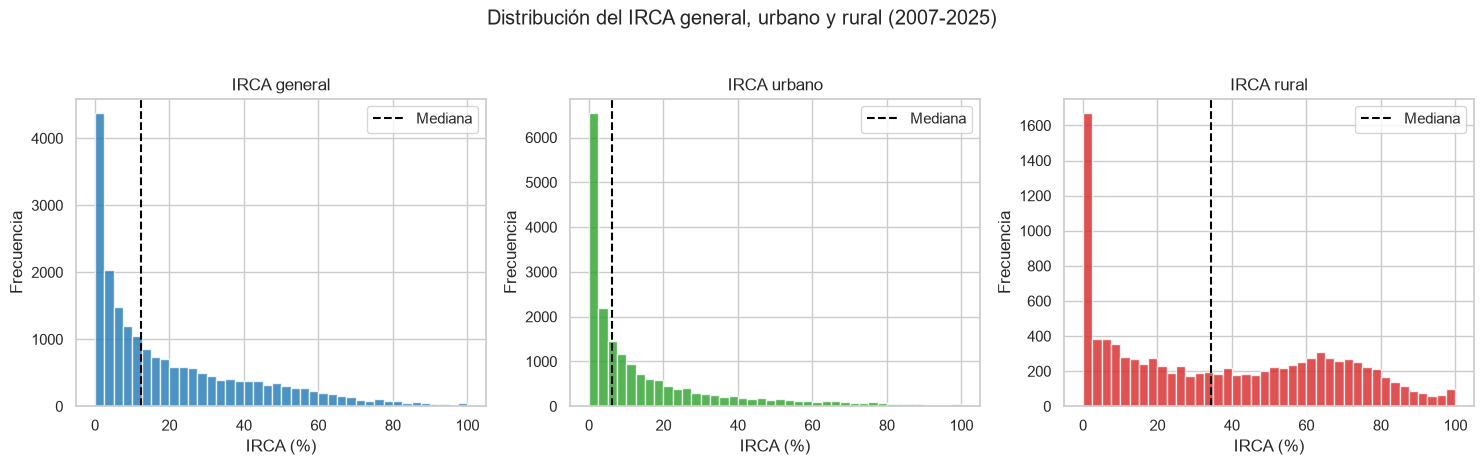

In [16]:
# --- Distribuciones comparadas (histogramas) ---
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, (col, titulo, color) in zip(
    axes,
    [
        (df["IRCA"], "IRCA general", "#1f77b4"),
        (df_irca_expl["IRCAurbano_num"], "IRCA urbano", "#2ca02c"),
        (df_irca_expl["IRCArural_num"], "IRCA rural", "#d62728"),
    ],
):
    ax.hist(col.dropna(), bins=40, color=color, alpha=0.8, edgecolor="white")
    ax.axvline(col.dropna().median(), color="black", linestyle="--", label="Mediana")
    ax.set_title(titulo)
    ax.set_xlabel("IRCA (%)")
    ax.set_ylabel("Frecuencia")
    ax.legend()

plt.suptitle("Distribución del IRCA general, urbano y rural (2007-2025)", y=1.03)
plt.tight_layout()
plt.show()

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_11492\117320040.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


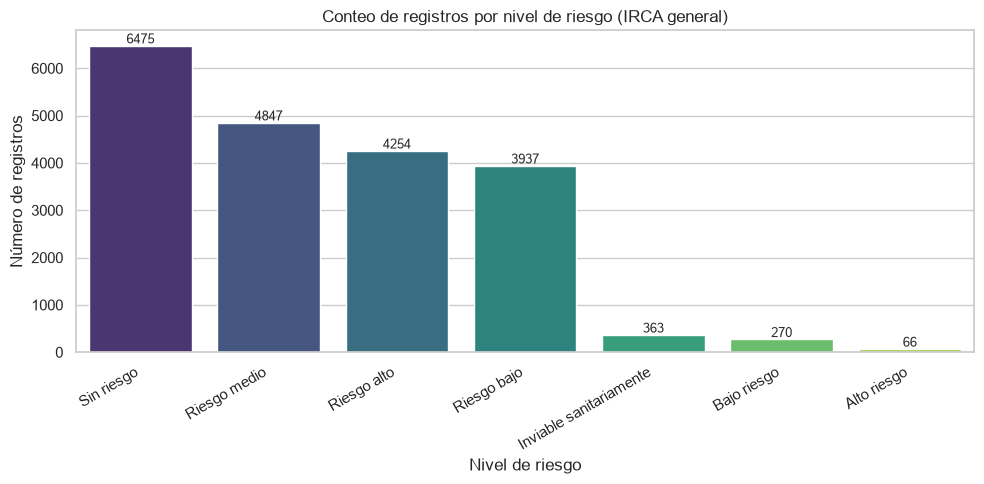

In [17]:
# --- Distribución del nivel de riesgo (categorías) ---
orden_niveles = [
    "Sin riesgo", "Riesgo bajo", "Bajo riesgo", "Riesgo medio",
    "Riesgo alto", "Alto riesgo", "Inviable sanitariamente",
]

conteo_niveles = df["Nivel de riesgo"].value_counts()

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    x=conteo_niveles.index, y=conteo_niveles.values,
    palette="viridis", ax=ax,
)
ax.set_title("Conteo de registros por nivel de riesgo (IRCA general)")
ax.set_xlabel("Nivel de riesgo")
ax.set_ylabel("Número de registros")
plt.xticks(rotation=30, ha="right")
for i, v in enumerate(conteo_niveles.values):
    ax.text(i, v + 50, str(v), ha="center", fontsize=9)
plt.tight_layout()
plt.show()

## 12. Cobertura geográfica y temporal

Se analiza la cobertura temporal (años disponibles) y geográfica (departamentos y municipios),
así como el número de registros por año.

In [18]:
# --- Cobertura temporal ---
print("Años disponibles:", sorted(df["Año"].unique().tolist()))
print(f"Período: {df['Año'].min()} - {df['Año'].max()} ({df['Año'].nunique()} años)")

# --- Registros por año ---
por_anio = df["Año"].value_counts().sort_index()
print("\nRegistros por año:")
print(por_anio.to_string())

Años disponibles: [2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]
Período: 2007 - 2025 (19 años)

Registros por año:
Año
2007    1026
2008    1060
2009    1069
2010    1085
2011    1082
2012    1085
2013    1089
2014    1089
2015    1056
2016    1061
2017    1086
2018    1109
2019    1113
2020    1037
2021    1073
2022     993
2023    1009
2024    1038
2025    1052


In [19]:
# --- Cobertura geográfica ---
print(f"Departamentos únicos: {df['Departamento'].nunique()}")
print(f"Municipios únicos:    {df['Municipio'].nunique()}")

# Registros por departamento (top 15)
por_depto = df["Departamento"].value_counts().head(15)
print("\nTop 15 departamentos por número de registros:")
print(por_depto.to_string())

Departamentos únicos: 34
Municipios únicos:    1016

Top 15 departamentos por número de registros:
Departamento
Antioquia             2349
Boyacá                2335
Cundinamarca          2177
Santander             1624
Nariño                1131
Tolima                 872
Bolívar                849
Norte de Santander     776
Valle del Cauca        766
Cauca                  755
Huila                  719
Magdalena              559
Caldas                 532
Meta                   527
Sucre                  501


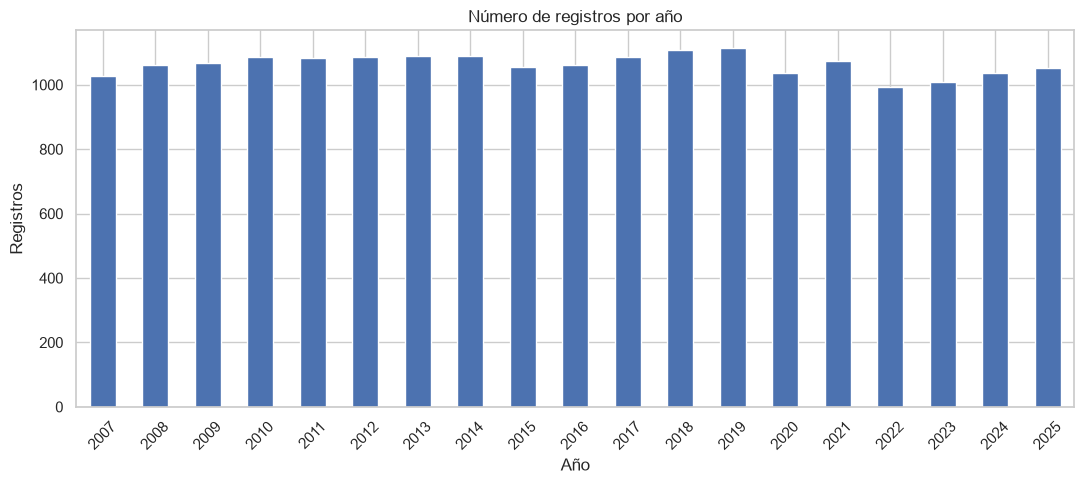

In [20]:
# --- Visualización: registros por año ---
fig, ax = plt.subplots(figsize=(11, 5))
por_anio.plot(kind="bar", ax=ax, color="#4C72B0", edgecolor="white")
ax.set_title("Número de registros por año")
ax.set_xlabel("Año")
ax.set_ylabel("Registros")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 13. Correlaciones y visualizaciones exploratorias

Se exploran las relaciones entre la variable IRCA (general, urbano y rural) y su evolución
temporal. Se construye una matriz de correlaciones entre las variables numéricas disponibles.

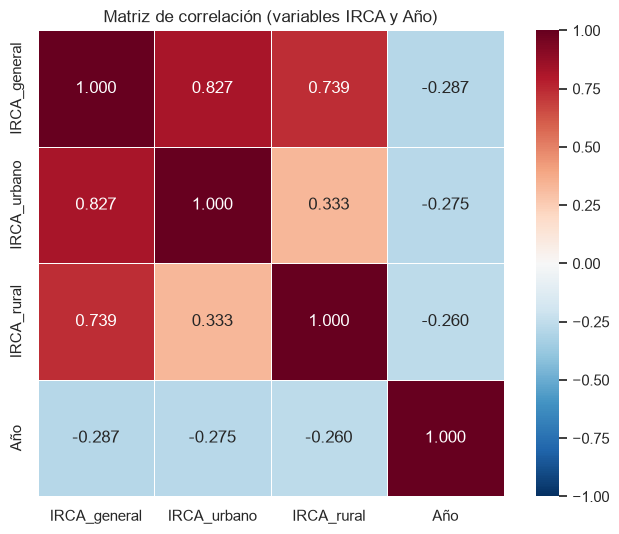

,IRCA_general,IRCA_urbano,IRCA_rural,Año
IRCA_general,1.000,0.827,0.739,-0.287
IRCA_urbano,0.827,1.000,0.333,-0.275
IRCA_rural,0.739,0.333,1.000,-0.260
Año,-0.287,-0.275,-0.260,1.000


In [21]:
# --- Matriz de correlación entre variables numéricas ---
df_corr = pd.DataFrame({
    "IRCA_general": df["IRCA"],
    "IRCA_urbano": df_irca_expl["IRCAurbano_num"],
    "IRCA_rural": df_irca_expl["IRCArural_num"],
    "Año": df["Año"],
})

corr = df_corr.corr()

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, cmap="RdBu_r", center=0, fmt=".3f",
            square=True, linewidths=0.5, ax=ax, vmin=-1, vmax=1)
ax.set_title("Matriz de correlación (variables IRCA y Año)")
plt.tight_layout()
plt.show()

corr.round(3)

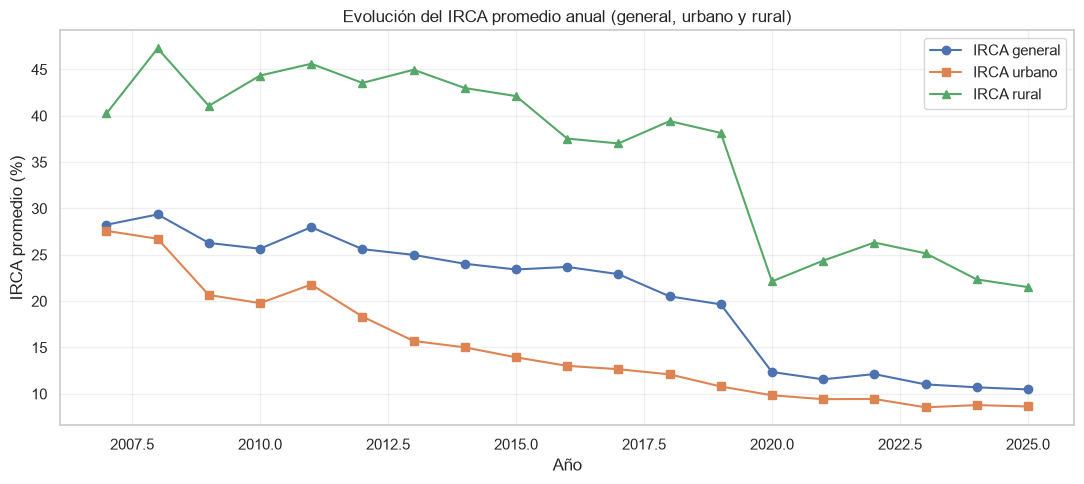

In [22]:
# --- Evolución temporal del IRCA (promedio anual) ---
irka_promedio_anual = df.groupby("Año")["IRCA"].mean()
irka_urbano_anual = df_irca_expl.groupby("Año")["IRCAurbano_num"].mean()
irka_rural_anual = df_irca_expl.groupby("Año")["IRCArural_num"].mean()

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(irka_promedio_anual.index, irka_promedio_anual.values,
        marker="o", label="IRCA general")
ax.plot(irka_urbano_anual.index, irka_urbano_anual.values,
        marker="s", label="IRCA urbano")
ax.plot(irka_rural_anual.index, irka_rural_anual.values,
        marker="^", label="IRCA rural")
ax.set_title("Evolución del IRCA promedio anual (general, urbano y rural)")
ax.set_xlabel("Año")
ax.set_ylabel("IRCA promedio (%)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 14. Resumen de hallazgos

### Hallazgos clave 

- El dataset tiene **20.212 filas** y **11 columnas**, sin valores nulos (`NaN`) ni duplicados.
- La variable principal es **IRCA** (numérica, 0–100 %), complementada por sus versiones
  **urbana** y **rural** (almacenadas como texto, con el marcador `"ND"`).
- Existen **32 departamentos** y **1.016 municipios**; cobertura temporal **2007–2025** (19 años).
- La columna `Nivel de riesgo` presenta **dos convenciones de etiquetas** mezcladas
  ("Riesgo bajo/medio/alto" y "Bajo riesgo/Alto riesgo"), lo que requerirá normalización en
  la etapa de limpieza.
- `IRCAurbano` tiene 1.277 valores `"ND"` y `IRCArural` 10.208 valores `"ND"` (ausencia de dato,
  no faltante real).


---
# Etapa 2 — Limpieza, selección y preparación de variables para clustering

El objetivo es dejar preparadas **dos
matrices de características** (Escenario A y Escenario B) listas para los algoritmos de la
Etapa 3, documentando cada decisión técnica y conservando la trazabilidad.

### Resumen de decisiones metodológicas de esta etapa

1. Separación de los registros agregados `#TODOS` (nivel departamental) del nivel municipal.
2. Codificación one-hot con `drop_first=False` (coherente con clustering, no regresión).
3. Estandarización de variables **numéricas** evitando que las dummies dominen las distancias.
4. Corrección de la justificación sobre valores atípicos (el escalado NO controla su influencia).
5. Construcción de **dos escenarios**: A = `IRCA`; B = `IRCA` + `Año`.
6. Conservación de variables descriptivas como **metadatos** para interpretación.
7. Documentación de dimensiones, transformaciones y justificaciones.
8. Trazabilidad y guardado de objetos para la Etapa 3.


## 2.1 Separación de los registros agregados `MunicipioCodigo == "#TODOS"`

In [24]:
# --- Identificación de los registros agregados departamentales ---
mask_todos = df["MunicipioCodigo"] == "#TODOS"

print(f"Total de registros:          {len(df):,}")
print(f"Registros #TODOS (depto):    {mask_todos.sum():,}")
print(f"Registros municipales:       {(~mask_todos).sum():,}")
print()
print("Significado: cuando MunicipioCodigo == '#TODOS', la fila representa el")
print("consolidado de TODO el departamento para un año dado (no un municipio).")

Total de registros:          20,212
Registros #TODOS (depto):    602
Registros municipales:       19,610

Significado: cuando MunicipioCodigo == '#TODOS', la fila representa el
consolidado de TODO el departamento para un año dado (no un municipio).


In [25]:
# --- Verificación del solapamiento entre niveles ---
sub_todos = df[mask_todos]
sub_mcpio = df[~mask_todos]

key_todos = set(map(tuple, sub_todos[["DepartamentoCodigo", "Año"]].drop_duplicates().values))
key_mcpio = set(map(tuple, sub_mcpio[["DepartamentoCodigo", "Año"]].drop_duplicates().values))

print("Combinaciones depto-año en #TODOS:      ", len(key_todos))
print("Combinaciones depto-año en municipios:  ", len(key_mcpio))
print("Combinaciones presentes en AMBOS niveles:", len(key_todos & key_mcpio))
print("Combinaciones SOLO en #TODOS:           ", len(key_todos - key_mcpio))

Combinaciones depto-año en #TODOS:       602
Combinaciones depto-año en municipios:   602
Combinaciones presentes en AMBOS niveles: 602
Combinaciones SOLO en #TODOS:            0


### Justificación

- Los 602 registros `#TODOS` son **agregados departamentales**: una fila por
  (departamento, año) que resume el IRCA de todo el departamento.
- Las 602 combinaciones depto-año de `#TODOS` **coinciden al 100%** con combinaciones ya
  presentes a nivel municipal (`SOLO en #TODOS = 0`). Es decir, cada agregado departamental
  coexiste con sus municipios desglosados.

**Mezclar** filas "departamento" y filas "municipio" en una misma matriz violaría el supuesto
de **unidades comparables**: un departamento aparecería dos veces (agregado + desglosado), lo
que distorsiona distancias y densidades locales (crítico para DBSCAN y K-means).

**Decisión:** se **separan**. El clustering trabajará con el nivel **municipal** (unidad más
granular y homogénea). Los 602 registros departamentales se **conservan** en
`df_departamental` para análisis complementarios / territoriales.

## 2.2 Tratamiento de valores faltantes y corrección de tipos

(Se retoma el diagnóstico de la Etapa 1 y se aplica el tratamiento.)
- No hay `NaN` reales, pero `IRCAurbano`/`IRCArural` usan el marcador `"ND"`.
- Se convierte `"ND"` a `NaN` y las columnas a numérico.
- Se unifica la inconsistencia de nombre del archipiélago (San Andrés "Y"/"y", código 88).

In [26]:
# --- Copia de trabajo limpia (df original permanece intacto) ---
df_clean = df.copy()

def texto_a_numerico(serie):
    return pd.to_numeric(serie.replace("ND", np.nan), errors="coerce")

df_clean["IRCAurbano"] = texto_a_numerico(df_clean["IRCAurbano"])
df_clean["IRCArural"] = texto_a_numerico(df_clean["IRCArural"])

# Unificación de nombre del archipiélago
df_clean["Departamento"] = df_clean["Departamento"].replace(
    {"Archipiélago de San Andrés, Providencia Y Santa Catalina":
     "Archipiélago de San Andrés, Providencia y Santa Catalina"}
)

# Códigos territoriales como string (identificadores, no magnitudes)
df_clean["DepartamentoCodigo"] = df_clean["DepartamentoCodigo"].astype(str)

print("Dataset limpio:", df_clean.shape, "(no se eliminaron filas ni columnas)")
print("Marcador 'ND' restante en IRCAurbano :", int((df_clean['IRCAurbano'].astype(str) == 'ND').sum()))
print("Marcador 'ND' restante en IRCArural  :", int((df_clean['IRCArural'].astype(str) == 'ND').sum()))

Dataset limpio: (20212, 11) (no se eliminaron filas ni columnas)
Marcador 'ND' restante en IRCAurbano : 0
Marcador 'ND' restante en IRCArural  : 0


## 2.3 Separación de niveles de agregación (conservando todo)

Se crean dos vistas a partir del dataset limpio:

- `df_municipal` — registros municipales (unidad de modelado).
- `df_departamental` — registros agregados `#TODOS` (análisis complementario).

In [27]:
df_municipal = df_clean[df_clean["MunicipioCodigo"] != "#TODOS"].reset_index(drop=True).copy()
df_departamental = df_clean[df_clean["MunicipioCodigo"] == "#TODOS"].reset_index(drop=True).copy()

print("Dataset limpio completo:      ", df_clean.shape)
print("Nivel municipal (modelado):   ", df_municipal.shape)
print("Nivel departamental (#TODOS): ", df_departamental.shape)
print()
print("Verificación:", len(df_municipal) + len(df_departamental), "=", len(df_clean))

Dataset limpio completo:       (20212, 11)
Nivel municipal (modelado):    (19610, 11)
Nivel departamental (#TODOS):  (602, 11)

Verificación: 20212 = 20212


## 2.4 Valores atípicos (IQR) sobre el nivel municipal

In [28]:
Q1 = df_municipal["IRCA"].quantile(0.25)
Q3 = df_municipal["IRCA"].quantile(0.75)
IQR = Q3 - Q1
li = Q1 - 1.5 * IQR
ls = Q3 + 1.5 * IQR

outliers = df_municipal[(df_municipal["IRCA"] < li) | (df_municipal["IRCA"] > ls)]

print(f"Q1={Q1:.3f}  Q3={Q3:.3f}  IQR={IQR:.3f}")
print(f"Límites IQR: [{li:.3f}, {ls:.3f}]")
print(f"Valores atípicos: {len(outliers):,} ({len(outliers)/len(df_municipal)*100:.2f}%)")
print(f"  - por debajo del límite inferior: {(df_municipal['IRCA'] < li).sum()}")
print(f"  - por encima del límite superior: {(df_municipal['IRCA'] > ls).sum()}")

Q1=3.100  Q3=33.000  IQR=29.900
Límites IQR: [-41.750, 77.850]
Valores atípicos: 426 (2.17%)
  - por debajo del límite inferior: 0
  - por encima del límite superior: 426


### Decisión (justificación corregida)

Se detectan **426 valores atípicos (2.17%)**, todos por encima del límite superior (IRCA
muy elevados). **No se eliminan ni se recortan**, por estas razones:

1. El IRCA es un valor físico **acotado en [0, 100]** y real: un IRCA de 100 es un municipio
   con agua *inviable sanitariamente*, un dato legítimo y de alto interés.
2. Eliminarlos sesgaría precisamente los grupos de mayor riesgo que el clustering busca
   identificar.

**Importante (corrección metodológica):** el `StandardScaler` **NO elimina ni controla la
influencia de los valores extremos**. La estandarización solo cambia la escala (media 0, desv.
1) pero conserva la posición relativa de los valores atípicos dentro de la distribución; por
tanto una observación extrema sigue estando lejos del centro del resto. Si se quisiera *reducir*
su influencia habría que recurrir a otras técnicas (p. ej. transformación logarítmica,
escalado robusto o `MinMaxScaler` recortado), que **no se aplican aquí** porque los valores
altos del IRCA son información valiosa y no ruido. Esta decisión se documenta explícitamente.

## 2.5 Selección de variables: qué entra al modelo y qué se conserva

| Columna | Naturaleza | Uso |
|---|---|---|
| `IRCA` | Numérica (0–100) | **Escenario A y B** (variable central) |
| `Año` | Numérica ordinal | **Escenario B** (dimensión temporal) |
| `IRCAurbano`, `IRCArural` | Numéricas con faltantes | No (redundantes con IRCA + NAs) |
| `Departamento`, `Municipio` | Categóricas geográficas | **Metadatos** (interpretación) |
| `MunicipioCodigo`, `DepartamentoCodigo` | Identificadores | **Metadatos** |
| `Nivel de riesgo` (gral/urbano/rural) | Categóricas derivadas del IRCA | No (redundantes) |

**Sobre el departamento:** no se incluye como variable de agrupamiento en los escenarios
principales. La razón es doble: (a) su one-hot generaría 33 columnas binarias que, en una
matriz con solo 1–2 variables numéricas, dominarían por completo las distancias euclidianas;
(b) el objetivo de los escenarios A y B es caracterizar el **perfil de riesgo** (y su evolución
temporal), no segmentar por geografía. El departamento se **conserva como metadato** para, en
la Etapa 3, *interpretar* los grupos resultantes (p. ej. qué departamentos predominan en cada
cluster), sin que participe en el cálculo de las distancias.

## 2.6 Codificación one-hot y `drop_first=False` (criterio para clustering)

Aunque el departamento **no** se incluye en los escenarios de modelado, se documenta el
criterio de codificación por si se desea una extensión territorial posterior:

- `drop_first=True` elimina una categoría de referencia para **evitar multicolinealidad
  perfecta en regresión**. En **clustering** ese problema no existe, porque los algoritmos de
  agrupamiento no estiman coeficientes ni asumen independencia lineal.
- `drop_first=False` representa las categorías de forma **simétrica** (cada departamento
  contribuye igual, sin una categoría "base" privilegiada), coherente con la noción de
  distancia entre observaciones.

**Conclusión:** si en una extensión futura se codificara `Departamento`, se usaría
`drop_first=False`. Además, dado el riesgo de dominancia de las dummies (§2.5), en ese caso
debería evaluarse un esquema de pesos o una métrica mixta (Gower).

In [29]:
# --- Ilustración de la diferencia (solo informativa) ---
d0 = pd.get_dummies(df_municipal["Departamento"], prefix="dep", drop_first=False)
d1 = pd.get_dummies(df_municipal["Departamento"], prefix="dep", drop_first=True)

print(f"Departamentos únicos: {df_municipal['Departamento'].nunique()}")
print(f"One-hot drop_first=False: {d0.shape}  (simétrico, recomendado para clustering)")
print(f"One-hot drop_first=True : {d1.shape}  (evita multicolinealidad, propio de regresión)")

Departamentos únicos: 33
One-hot drop_first=False: (19610, 33)  (simétrico, recomendado para clustering)
One-hot drop_first=True : (19610, 32)  (evita multicolinealidad, propio de regresión)


## 2.7 Estandarización de variables y distancias

**Métrica:** distancia euclidiana (estándar para K-means, jerárquico aglomerativo y DBSCAN).

**Comparación:**
- `StandardScaler` (z-score): media 0, desviación 1. Adecuado cuando las variables tienen
  magnitudes distintas; es menos sensible a la escala que el rango min-max.
- `MinMaxScaler`: lleva a [0,1], pero es **muy sensible a valores extremos** (un solo valor
  atípico comprime todo el resto). Dado que el IRCA tiene cola derecha (valores hasta 100),
  se descarta para este proyecto.

**Elección:** `StandardScaler`.

**Sobre las variables binarias (dummies de departamento):** en esta revisión **no forman parte
de los escenarios**, por lo que ya no existe el riesgo de que adquieran influencia desproporcionada
sobre las distancias. Se evita así el problema de dominancia planteado en el punto 3 de la
revisión. Solo se estandarizan las variables numéricas continuas (`IRCA` y `Año`).

## 2.8 Definición de los dos escenarios

### Escenario A — solo `IRCA`
Representa el **perfil de riesgo puro**: agrupa municipios según su nivel de riesgo de calidad
del agua, sin considerar territorio ni tiempo. Es la medida más directa del objetivo del
proyecto.

### Escenario B — `IRCA` y `Año`
Añade la **dimensión temporal**: agrupa municipios según su nivel de riesgo **y el año** de la
medición. La correlación IRCA–Año es moderada negativa (≈ -0.29), por lo que el año aporta
información no redundante sobre la evolución temporal del riesgo.

Ambas matrices se construyen sobre el **nivel municipal** (`df_municipal`).

In [30]:
# --- Correlación IRCA vs Año (justificación de incluir Año en el escenario B) ---
corr_irka_anio = df_municipal["IRCA"].corr(df_municipal["Año"])
print(f"Correlación IRCA-Año (nivel municipal): {corr_irka_anio:.4f}")

Correlación IRCA-Año (nivel municipal): -0.2850


## 2.9 Construcción de las matrices de características

In [31]:
# --- Escenario A: solo IRCA ---
X_A = df_municipal[["IRCA"]].reset_index(drop=True)
feature_names_A = X_A.columns.tolist()

# --- Escenario B: IRCA + Año ---
X_B = df_municipal[["IRCA", "Año"]].reset_index(drop=True)
feature_names_B = X_B.columns.tolist()

print("Escenario A (IRCA):     ", X_A.shape, "-> columnas:", feature_names_A)
print("Escenario B (IRCA+Año): ", X_B.shape, "-> columnas:", feature_names_B)

# --- Metadatos para interpretar resultados (se conservan) ---
metadatos = df_municipal[
    ["Departamento", "DepartamentoCodigo", "Municipio", "MunicipioCodigo",
     "Año", "IRCAurbano", "IRCArural",
     "Nivel de riesgo", "Nivel de riesgo urbano", "Nivel de riesgo rural"]
].reset_index(drop=True)

print()
print("Metadatos conservados para interpretación:", metadatos.shape)
print(metadatos.columns.tolist())

Escenario A (IRCA):      (19610, 1) -> columnas: ['IRCA']
Escenario B (IRCA+Año):  (19610, 2) -> columnas: ['IRCA', 'Año']

Metadatos conservados para interpretación: (19610, 10)
['Departamento', 'DepartamentoCodigo', 'Municipio', 'MunicipioCodigo', 'Año', 'IRCAurbano', 'IRCArural', 'Nivel de riesgo', 'Nivel de riesgo urbano', 'Nivel de riesgo rural']


In [32]:
# --- Vista previa de las matrices y metadatos ---
print("X_A (Escenario A):"); print(X_A.head(3).to_string(index=False))
print()
print("X_B (Escenario B):"); print(X_B.head(3).to_string(index=False))
print()
print("Metadatos:"); print(metadatos.head(3).to_string(index=False))

X_A (Escenario A):
  IRCA
 3.600
 2.800
22.800

X_B (Escenario B):
  IRCA  Año
 3.600 2024
 2.800 2024
22.800 2024

Metadatos:
Departamento DepartamentoCodigo           Municipio MunicipioCodigo  Año  IRCAurbano  IRCArural Nivel de riesgo Nivel de riesgo urbano Nivel de riesgo rural
Bogotá, D.C.                 11        Bogotá, D.C.           11001 2024       1.100     14.800      Sin riesgo             Sin riesgo          Riesgo medio
     Bolívar                 13 Cartagena de Indias           13001 2024       2.900      2.400      Sin riesgo             Sin riesgo            Sin riesgo
     Bolívar                 13                Achí           13006 2024      22.800        NaN    Riesgo medio           Riesgo medio                    ND


## 2.10 Estandarización de las matrices

Se aplica `StandardScaler` a las variables numéricas de cada escenario. Como en esta revisión
solo hay variables numéricas continuas (`IRCA` y `Año`), no hay dummies que requieran
tratamiento especial.

In [33]:
from sklearn.preprocessing import StandardScaler

scaler_A = StandardScaler()
scaler_B = StandardScaler()

X_A_scaled = pd.DataFrame(scaler_A.fit_transform(X_A), columns=feature_names_A)
X_B_scaled = pd.DataFrame(scaler_B.fit_transform(X_B), columns=feature_names_B)

print("Escenario A estandarizado:", X_A_scaled.shape)
print("Escenario B estandarizado:", X_B_scaled.shape)
print()
print("Verificación (media ≈ 0, desvío ≈ 1):")
for nombre, Xs in [("A", X_A_scaled), ("B", X_B_scaled)]:
    print(f"  Escenario {nombre}: medias={dict(Xs.mean().round(5))}   desvíos={dict(Xs.std().round(5))}")

Escenario A estandarizado: (19610, 1)
Escenario B estandarizado: (19610, 2)

Verificación (media ≈ 0, desvío ≈ 1):
  Escenario A: medias={'IRCA': np.float64(-0.0)}   desvíos={'IRCA': np.float64(1.00003)}
  Escenario B: medias={'IRCA': np.float64(-0.0), 'Año': np.float64(-0.0)}   desvíos={'IRCA': np.float64(1.00003), 'Año': np.float64(1.00003)}


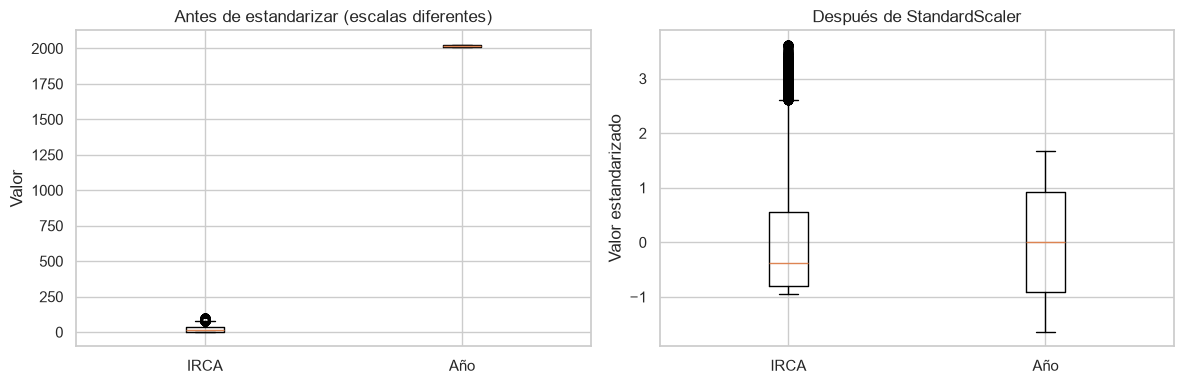

In [34]:
# --- Verificación visual del efecto del escalado ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

b1 = axes[0].boxplot([X_B["IRCA"], X_B["Año"]])
axes[0].set_xticklabels(["IRCA", "Año"])
axes[0].set_title("Antes de estandarizar (escalas diferentes)")
axes[0].set_ylabel("Valor")

b2 = axes[1].boxplot([X_B_scaled["IRCA"], X_B_scaled["Año"]])
axes[1].set_xticklabels(["IRCA", "Año"])
axes[1].set_title("Después de StandardScaler")
axes[1].set_ylabel("Valor estandarizado")

plt.tight_layout()
plt.show()

## 2.11 Comparación de dimensiones, trazabilidad y guardado

Se resumen las dimensiones de todos los objetos generados y se guardan los necesarios para la
Etapa 3, conservando los datos originales.

In [35]:
# --- Resumen comparativo de dimensiones ---
resumen = pd.DataFrame({
    "Objeto": [
        "df (original)",
        "df_clean (limpio)",
        "df_municipal (modelado)",
        "df_departamental (#TODOS)",
        "X_A (IRCA, sin escala)",
        "X_A_scaled (IRCA, escalado)",
        "X_B (IRCA+Año, sin escala)",
        "X_B_scaled (IRCA+Año, escalado)",
        "metadatos",
    ],
    "Filas": [
        df.shape[0], df_clean.shape[0], df_municipal.shape[0], df_departamental.shape[0],
        X_A.shape[0], X_A_scaled.shape[0], X_B.shape[0], X_B_scaled.shape[0],
        metadatos.shape[0],
    ],
    "Columnas": [
        df.shape[1], df_clean.shape[1], df_municipal.shape[1], df_departamental.shape[1],
        X_A.shape[1], X_A_scaled.shape[1], X_B.shape[1], X_B_scaled.shape[1],
        metadatos.shape[1],
    ],
})
resumen

,Objeto,Filas,Columnas
0,df (original),20212,11
1,df_clean (limpio),20212,11
2,df_municipal (modelado),19610,11
3,df_departamental (#TODOS),602,11
4,"X_A (IRCA, sin escala)",19610,1
5,"X_A_scaled (IRCA, escalado)",19610,1
6,"X_B (IRCA+Año, sin escala)",19610,2
7,"X_B_scaled (IRCA+Año, escalado)",19610,2
8,metadatos,19610,10


In [36]:
# --- Verificación de integridad ---
import numpy as np
for nombre, X in [("X_A", X_A), ("X_A_scaled", X_A_scaled),
                  ("X_B", X_B), ("X_B_scaled", X_B_scaled)]:
    faltantes = int(X.isna().sum().sum())
    infinitos = int(np.isinf(X.to_numpy(dtype='float64', na_value=np.nan)).sum())
    print(f"{nombre}: filas={X.shape[0]}, columnas={X.shape[1]}, faltantes={faltantes}, infinitos={infinitos}")

X_A: filas=19610, columnas=1, faltantes=0, infinitos=0
X_A_scaled: filas=19610, columnas=1, faltantes=0, infinitos=0
X_B: filas=19610, columnas=2, faltantes=0, infinitos=0
X_B_scaled: filas=19610, columnas=2, faltantes=0, infinitos=0


In [37]:
# --- Guardado de objetos para la Etapa 3 ---
import pickle

objetos_etapa3 = {
    # Datos originales y de limpieza (trazabilidad)
    "df": df,
    "df_clean": df_clean,
    "df_municipal": df_municipal,
    "df_departamental": df_departamental,
    # Escenario A
    "X_A": X_A,
    "X_A_scaled": X_A_scaled,
    "feature_names_A": feature_names_A,
    "scaler_A": scaler_A,
    # Escenario B
    "X_B": X_B,
    "X_B_scaled": X_B_scaled,
    "feature_names_B": feature_names_B,
    "scaler_B": scaler_B,
    # Metadatos para interpretación
    "metadatos": metadatos,
}

with open("data_etapa2_preparados.pkl", "wb") as f:
    pickle.dump(objetos_etapa3, f)

print("Preparación guardada en: data_etapa2_preparados.pkl")
print()
print("Etapa 2 (revisada) completada — listo para revisión antes de la Etapa 3:")
print("  Escenario A (calidad):      ", X_A_scaled.shape, "| variables:", feature_names_A)
print("  Escenario B (calidad+tiempo):", X_B_scaled.shape, "| variables:", feature_names_B)

Preparación guardada en: data_etapa2_preparados.pkl

Etapa 2 (revisada) completada — listo para revisión antes de la Etapa 3:
  Escenario A (calidad):       (19610, 1) | variables: ['IRCA']
  Escenario B (calidad+tiempo): (19610, 2) | variables: ['IRCA', 'Año']


---
# Etapa 3 — Aplicación de algoritmos de clustering

En esta etapa se aplican los algoritmos de aprendizaje no supervisado sobre las dos matrices
preparadas en la Etapa 2:

- **Escenario A:** `IRCA` (perfil de riesgo puro).
- **Escenario B:** `IRCA` + `Año` (riesgo + dimensión temporal).

La etapa se desarrolla por **subetapas**, una para cada algoritmo, para su revisión incremental:

1. **Subetapa 3.1 — K-Means** (esta sección).
2. Subetapa 3.2 — DBSCAN *(pendiente de revisión)*.
3. Subetapa 3.3 — Clustering jerárquico *(pendiente de revisión)*.

Cada algoritmo se justifica en parámetros, se evalúa en número/tamaño de grupos y se analiza
con los **metadatos** (departamento, municipio, niveles de riesgo) sin modificar los datos
originales.

---
## 3.1 K-Means

### Descripción del algoritmo

K-Means particiona las observaciones en **K grupos** minimizando la suma de distancias
euclidianas al centroide de cada grupo. Requiere:

- Especificar **K** a priori.
- Datos **escalados** (se usan las matrices estandarizadas).
- Es sensible a la **inicialización** de los centroides (se fija semilla para reproducibilidad).

### Parámetros utilizados

| Parámetro | Valor | Justificación |
|---|---|---|
| `n_clusters` | 3 (principal) | Elegido por silueta + interpretabilidad (ver abajo) |
| `init` | `k-means++` (por defecto) | Inicialización inteligente que mejora convergencia |
| `n_init` | 10 | Ejecuciones con distintas semillas para evitar óptimos locales |
| `max_iter` | 300 (por defecto) | Suficiente para convergencia |
| `random_state` | 42 | Reproducibilidad de la partición |

### El problema de elegir K

Se evalúan dos criterios complementarios:

1. **Método del codo** (inercia vs. K): busca el punto donde la reducción de inercia deja de
   ser apreciable.
2. **Coeficiente de silueta**: mide cuán bien separados están los grupos (rango -1 a 1).

In [38]:
# --- Importaciones específicas de clustering ---
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples

# --- Carga de los objetos preparados en la Etapa 2 ---
import pickle

with open("data_etapa2_preparados.pkl", "rb") as f:
    datos = pickle.load(f)

X_A = datos["X_A_scaled"]        # Escenario A (estandarizado)
X_B = datos["X_B_scaled"]        # Escenario B (estandarizado)
metadatos = datos["metadatos"]   # metadatos interpretativos
df_mun = datos["df_municipal"]   # nivel municipal (para IRCA/Año en escala original)

print("Escenario A:", X_A.shape)
print("Escenario B:", X_B.shape)
print("Metadatos: ", metadatos.shape)

Escenario A: (19610, 1)
Escenario B: (19610, 2)
Metadatos:  (19610, 10)


### 3.1.1 Método del codo (inercia vs K)

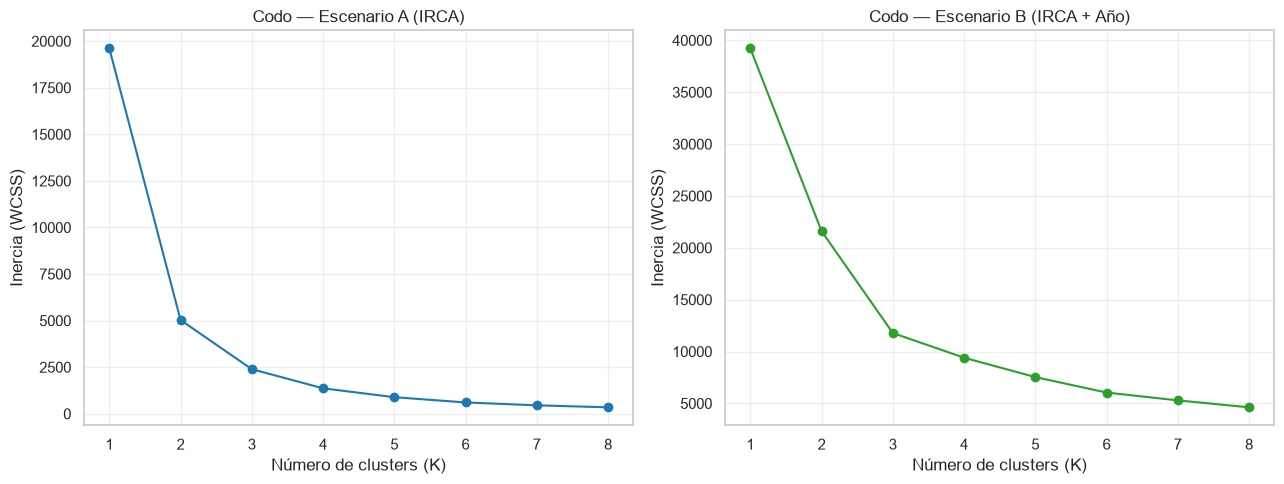

,K,Inercia A,Inercia B
0,1,19610.000,39220.000
1,2,5028.460,21601.870
2,3,2391.880,11783.790
3,4,1364.000,9403.900
4,5,888.050,7535.890
5,6,606.080,6045.790
6,7,451.760,5292.420
7,8,344.260,4621.880


In [39]:
# --- Inercia para K = 1..8 en ambos escenarios ---
rango_k = range(1, 9)
inercia_A = []
inercia_B = []

for k in rango_k:
    inercia_A.append(KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_A).inertia_)
    inercia_B.append(KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_B).inertia_)

# --- Gráfica del codo ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(list(rango_k), inercia_A, marker="o", color="#1f77b4")
axes[0].set_title("Codo — Escenario A (IRCA)")
axes[0].set_xlabel("Número de clusters (K)")
axes[0].set_ylabel("Inercia (WCSS)")
axes[0].set_xticks(list(rango_k))
axes[0].grid(True, alpha=0.3)

axes[1].plot(list(rango_k), inercia_B, marker="o", color="#2ca02c")
axes[1].set_title("Codo — Escenario B (IRCA + Año)")
axes[1].set_xlabel("Número de clusters (K)")
axes[1].set_ylabel("Inercia (WCSS)")
axes[1].set_xticks(list(rango_k))
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# --- Tabla de inercia ---
tabla_inercia = pd.DataFrame({
    "K": list(rango_k),
    "Inercia A": np.round(inercia_A, 2),
    "Inercia B": np.round(inercia_B, 2),
})
tabla_inercia

### 3.1.2 Coeficiente de silueta

Se calcula la silueta para distintos K (2 a 5) en ambos escenarios. Un valor más alto indica
grupos más compactos y mejor separados.

In [40]:
# --- Silueta para K = 2..5 ---
k_probar = [2, 3, 4, 5]
silueta_A = []
silueta_B = []

for k in k_probar:
    lab_A = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_A)
    lab_B = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_B)
    silueta_A.append(silhouette_score(X_A, lab_A))
    silueta_B.append(silhouette_score(X_B, lab_B))

tabla_silueta = pd.DataFrame({
    "K": k_probar,
    "Silueta A": np.round(silueta_A, 4),
    "Silueta B": np.round(silueta_B, 4),
})
tabla_silueta

,K,Silueta A,Silueta B
0,2,0.691,0.419
1,3,0.645,0.469
2,4,0.625,0.460
3,5,0.603,0.397


### Elección de K

- **Escenario A:** la métrica de silueta favorece claramente **K=2** (0.691) frente a K=3
  (0.645). Sin embargo, se adopta **K=3** como solución principal por **pertinencia analítica**,
  no porque K=3 maximice la silueta:

  - Con K=2, la partición separa el IRCA en dos bloques (valores bajos vs. altos), dejando en
    un único grupo un rango de riesgo muy amplio y heterogéneo.
  - Con K=3 se obtiene una segmentación más **graduada y accionable** (riesgo bajo / medio / alto),
    que facilita la interpretación para la toma de decisiones. La pérdida de silueta (≈0.046)
    es modesta.

  > **Aclaración:** los clusters de K-Means **no equivalen** a las categorías normativas del
  > IRCA (Resolución 2115 de 2007). Los límites de los clusters son **umbrales estimados por el
  > algoritmo** a partir de la distribución de los datos, no los cortes fijos de la normativa.
  > La semejanza es solo aproximada y se usa para *describir* los grupos, no como clasificación
  > oficial.

- **Escenario B:** la silueta máxima es **K=3** (0.469), por lo que K=3 coincide aquí con el
  criterio métrico y, además, produce grupos interpretables por nivel de riesgo **y por época**.

Se documenta K=3 como elección principal en ambos escenarios (en A, por pertinencia analítica;
en B, porque además coincide con la mejor silueta). K=2 queda documentado como alternativa
válida para el Escenario A.

### 3.1.3 Ajuste del modelo (K=3) y tamaño de los clusters

In [41]:
# --- Ajuste K-Means con K=3 en ambos escenarios ---
kmeans_A = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_B = KMeans(n_clusters=3, random_state=42, n_init=10)

labels_A = kmeans_A.fit_predict(X_A)
labels_B = kmeans_B.fit_predict(X_B)

# --- Tamaño de los clusters ---
tam_A = pd.Series(labels_A).value_counts().sort_index()
tam_B = pd.Series(labels_B).value_counts().sort_index()

print("Escenario A (IRCA) — tamaño de clusters:")
for k, v in tam_A.items():
    print(f"  Cluster {k}: {v:,} ({v/len(labels_A)*100:.1f}%)")
print()
print("Escenario B (IRCA+Año) — tamaño de clusters:")
for k, v in tam_B.items():
    print(f"  Cluster {k}: {v:,} ({v/len(labels_B)*100:.1f}%)")

Escenario A (IRCA) — tamaño de clusters:
  Cluster 0: 5,092 (26.0%)
  Cluster 1: 11,682 (59.6%)
  Cluster 2: 2,836 (14.5%)

Escenario B (IRCA+Año) — tamaño de clusters:
  Cluster 0: 4,506 (23.0%)
  Cluster 1: 7,012 (35.8%)
  Cluster 2: 8,092 (41.3%)


In [42]:
# --- Centroides (en la escala estandarizada) ---
print("Centroides Escenario A (z-score de IRCA):")
print(pd.DataFrame(kmeans_A.cluster_centers_, columns=["IRCA_z"]).round(3).to_string())
print()
print("Centroides Escenario B (z-score de IRCA y Año):")
print(pd.DataFrame(kmeans_B.cluster_centers_, columns=["IRCA_z", "Año_z"]).round(3).to_string())

Centroides Escenario A (z-score de IRCA):
   IRCA_z
0   0.483
1  -0.678
2   1.941

Centroides Escenario B (z-score de IRCA y Año):
   IRCA_z  Año_z
0   1.553 -0.481
1  -0.393 -0.811
2  -0.524  0.970


### 3.1.4 Caracterización de los clusters (escala original y niveles de riesgo)

Se unen las etiquetas de cluster con los metadatos y el IRCA/Año en escala original para
interpretar cada grupo. **Antes** se verifica que las matrices, los metadatos y las etiquetas
estén alineadas fila a fila (mismo índice y longitud), para no cruzar información de
municipios distintos.

In [43]:
# --- Verificación de alineación entre matrices, metadatos y etiquetas ---
# (Trazabilidad: garantiza que no se cruzan filas de municipios distintos.)
n = len(df_mun)
assert len(metadatos) == n and len(X_A) == n and len(X_B) == n, "Longitudes distintas"
assert metadatos.index.equals(df_mun.index), "Índices de metadatos y df_municipal no coinciden"
al_A = len(labels_A) == n
al_B = len(labels_B) == n
print(f"Filas: df_municipal={n}, metadatos={len(metadatos)}, X_A={len(X_A)}, X_B={len(X_B)}")
print(f"Etiquetas K-Means: len(labels_A)={len(labels_A)} (coincide: {al_A}), "
      f"len(labels_B)={len(labels_B)} (coincide: {al_B})")
print("Índices de metadatos == df_municipal:", metadatos.index.equals(df_mun.index))
print()

# --- DataFrame de caracterización (construido con verificación de alineación) ---
caracterizacion = metadatos.copy()
caracterizacion["IRCA"] = df_mun["IRCA"].to_numpy()
caracterizacion["Año"] = df_mun["Año"].to_numpy()
caracterizacion["cluster_A"] = labels_A
caracterizacion["cluster_B"] = labels_B

# --- Resumen del escenario A ---
print("===== ESCENARIO A (IRCA) — perfil de cada cluster =====")
for c in np.unique(labels_A):
    sub = caracterizacion[caracterizacion["cluster_A"] == c]
    print(f"\nCluster {c} (n={len(sub):,}):")
    print(f"  IRCA: media={sub['IRCA'].mean():.2f}, mediana={sub['IRCA'].median():.2f}, "
          f"min={sub['IRCA'].min():.2f}, max={sub['IRCA'].max():.2f}")

Filas: df_municipal=19610, metadatos=19610, X_A=19610, X_B=19610
Etiquetas K-Means: len(labels_A)=19610 (coincide: True), len(labels_B)=19610 (coincide: True)
Índices de metadatos == df_municipal: True

===== ESCENARIO A (IRCA) — perfil de cada cluster =====

Cluster 0 (n=5,092):
  IRCA: media=31.20, mediana=30.20, min=18.60, max=47.20

Cluster 1 (n=11,682):
  IRCA: media=5.82, mediana=4.30, min=0.00, max=18.50

Cluster 2 (n=2,836):
  IRCA: media=63.18, mediana=59.80, min=47.30, max=100.00


In [44]:
# --- Resumen del escenario B ---
print("===== ESCENARIO B (IRCA + Año) — perfil de cada cluster =====")
for c in np.unique(labels_B):
    sub = caracterizacion[caracterizacion["cluster_B"] == c]
    print(f"\nCluster {c} (n={len(sub):,}):")
    print(f"  IRCA: media={sub['IRCA'].mean():.2f}, mediana={sub['IRCA'].median():.2f}")
    print(f"  Año:  media={sub['Año'].mean():.2f}, min={sub['Año'].min()}, max={sub['Año'].max()}")

===== ESCENARIO B (IRCA + Año) — perfil de cada cluster =====

Cluster 0 (n=4,506):
  IRCA: media=54.73, mediana=51.85
  Año:  media=2013.33, min=2007, max=2025

Cluster 1 (n=7,012):
  IRCA: media=12.08, mediana=9.70
  Año:  media=2011.54, min=2007, max=2016

Cluster 2 (n=8,092):
  IRCA: media=9.23, mediana=5.50
  Año:  media=2021.22, min=2017, max=2025


### 3.1.5 Visualizaciones

- **Escenario A:** histograma del IRCA por cluster (1D).
- **Escenario B:** diagrama de dispersión IRCA vs Año coloreado por cluster (2D).

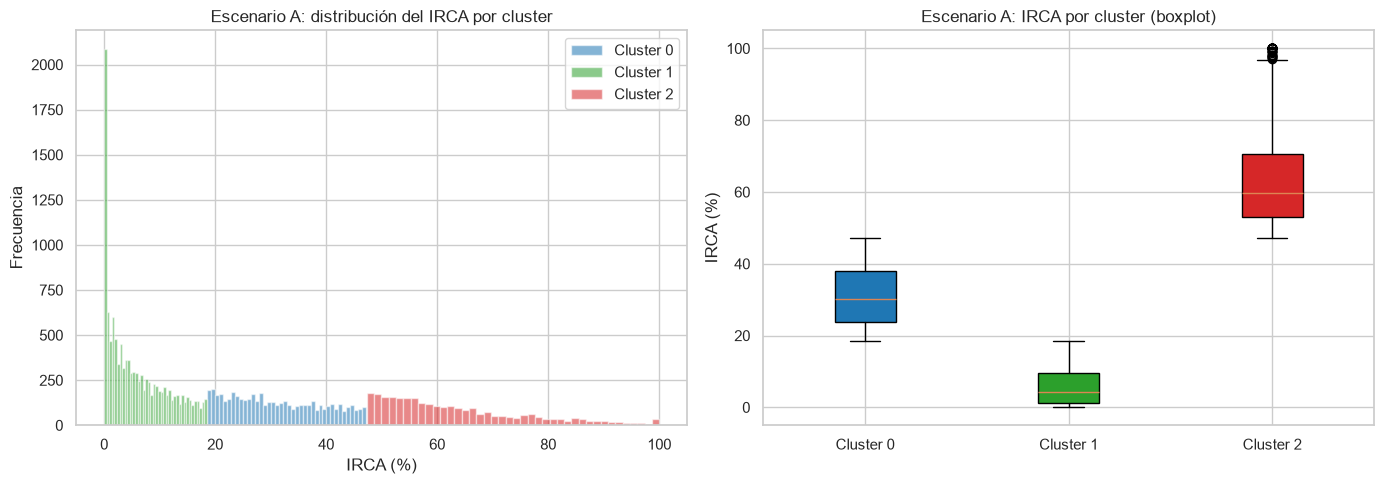

In [45]:
# --- Escenario A: histograma de IRCA por cluster ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colores = ["#1f77b4", "#2ca02c", "#d62728"]

for c in np.unique(labels_A):
    sub = caracterizacion[caracterizacion["cluster_A"] == c]
    axes[0].hist(sub["IRCA"], bins=40, alpha=0.55, label=f"Cluster {c}", color=colores[c])
axes[0].set_title("Escenario A: distribución del IRCA por cluster")
axes[0].set_xlabel("IRCA (%)")
axes[0].set_ylabel("Frecuencia")
axes[0].legend()

# diagrama de caja por cluster (A)
bplot = axes[1].boxplot(
    [caracterizacion[caracterizacion["cluster_A"] == c]["IRCA"] for c in np.unique(labels_A)],
    patch_artist=True,
)
for patch, color in zip(bplot["boxes"], colores):
    patch.set_facecolor(color)
axes[1].set_xticklabels([f"Cluster {c}" for c in np.unique(labels_A)])
axes[1].set_title("Escenario A: IRCA por cluster (boxplot)")
axes[1].set_ylabel("IRCA (%)")

plt.tight_layout()
plt.show()

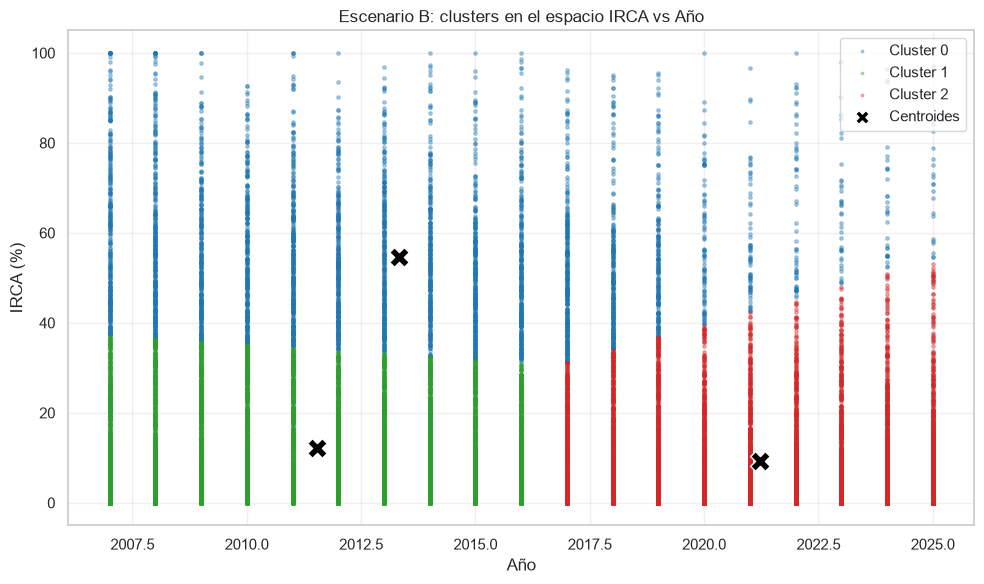

In [46]:
# --- Escenario B: dispersión IRCA vs Año por cluster ---
fig, ax = plt.subplots(figsize=(10, 6))

for c in np.unique(labels_B):
    sub = caracterizacion[caracterizacion["cluster_B"] == c]
    ax.scatter(sub["Año"], sub["IRCA"], s=6, alpha=0.35,
               label=f"Cluster {c}", color=colores[c])

# Centroides en escala original (des-estandarizar)
cent_A = kmeans_B.cluster_centers_[:, 0] * datos["scaler_B"].scale_[0] + datos["scaler_B"].mean_[0]
cent_Año = kmeans_B.cluster_centers_[:, 1] * datos["scaler_B"].scale_[1] + datos["scaler_B"].mean_[1]
ax.scatter(cent_Año, cent_A, marker="X", s=200, c="black", edgecolor="white",
           label="Centroides")

ax.set_title("Escenario B: clusters en el espacio IRCA vs Año")
ax.set_xlabel("Año")
ax.set_ylabel("IRCA (%)")
ax.legend(markerscale=0.7)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 3.1.6 Distribución de niveles de riesgo por cluster

Se cruzan los clusters con la categoría `Nivel de riesgo` (variable derivada informativa,
**no usada en el modelo**) para *describir* la composición de cada grupo.

> **Aclaración importante:** un cluster **no corresponde** a una categoría normativa del IRCA.
> Los clusters son particiones estimadas por K-Means sobre la distribución de los datos, y un
> mismo cluster puede contener municipios de varios niveles de riesgo (los límites de K-Means
> no coinciden exactamente con los umbrales de la Resolución 2115 de 2007). La tabla cruzada
> solo muestra *qué tan bien* los clusters se aproximan a la escala normativa.

In [47]:
# --- Tabla cruzada cluster vs nivel de riesgo (Escenario A) ---
cruce_A = pd.crosstab(caracterizacion["cluster_A"], caracterizacion["Nivel de riesgo"])
print("Escenario A — cluster (filas) vs nivel de riesgo (columnas):")
print(cruce_A.to_string())
print()
cruce_B = pd.crosstab(caracterizacion["cluster_B"], caracterizacion["Nivel de riesgo"])
print("Escenario B — cluster (filas) vs nivel de riesgo (columnas):")
print(cruce_B.to_string())

Escenario A — cluster (filas) vs nivel de riesgo (columnas):
Nivel de riesgo  Alto riesgo  Bajo riesgo  Inviable sanitariamente  Riesgo alto  Riesgo bajo  Riesgo medio  Sin riesgo
cluster_A                                                                                                             
0                         30            0                        0         1735            0          3327           0
1                          0          256                        0            0         3774          1277        6375
2                         35            0                      358         2443            0             0           0

Escenario B — cluster (filas) vs nivel de riesgo (columnas):
Nivel de riesgo  Alto riesgo  Bajo riesgo  Inviable sanitariamente  Riesgo alto  Riesgo bajo  Riesgo medio  Sin riesgo
cluster_B                                                                                                             
0                         27            0   

### 3.1.7 Municipios y departamentos por grupo

Se identifican los departamentos más frecuentes en cada cluster usando los metadatos.

> **Interpretación con cautela:** la frecuencia de un departamento en un cluster está
> fuertemente condicionada por su **número total de municipios** (departamentos con más
> municipios tienden a aparecer más en todos los grupos). Por tanto, "departamento más
> frecuente" **no implica** que ese departamento tenga mayor riesgo; conviene leerlo en
> términos relativos al tamaño del departamento, no como indicador de criticidad.

In [48]:
# --- Top departamentos por cluster (Escenario A) ---
print("Escenario A — top departamentos por cluster:")
for c in np.unique(labels_A):
    sub = caracterizacion[caracterizacion["cluster_A"] == c]
    top = sub["Departamento"].value_counts().head(5)
    print(f"  Cluster {c}: " + ", ".join(f"{d} ({n})" for d, n in top.items()))
print()
print("Escenario B — top departamentos por cluster:")
for c in np.unique(labels_B):
    sub = caracterizacion[caracterizacion["cluster_B"] == c]
    top = sub["Departamento"].value_counts().head(5)
    print(f"  Cluster {c}: " + ", ".join(f"{d} ({n})" for d, n in top.items()))

Escenario A — top departamentos por cluster:
  Cluster 0: Boyacá (1082), Nariño (452), Santander (439), Bolívar (295), Cundinamarca (261)
  Cluster 1: Antioquia (2074), Cundinamarca (1864), Santander (1068), Boyacá (987), Cauca (535)
  Cluster 2: Nariño (440), Bolívar (260), Huila (249), Boyacá (247), Caldas (245)

Escenario B — top departamentos por cluster:
  Cluster 0: Boyacá (682), Nariño (658), Bolívar (363), Huila (338), Caldas (291)
  Cluster 1: Antioquia (1123), Cundinamarca (1064), Boyacá (702), Santander (697), Valle del Cauca (327)
  Cluster 2: Antioquia (1078), Cundinamarca (1024), Boyacá (932), Santander (713), Tolima (364)


### 3.1.8 Métricas de evaluación

Para K-Means se reportan las métricas aplicables:

- **Inercia (WCSS):** suma de distancias al centroide (menor = más compacto), usada para el codo.
- **Coeficiente de silueta:** calidad global de la partición (sin etiquetas verdaderas).

In [49]:
# --- Métricas finales para K=3 ---
sil_A = silhouette_score(X_A, labels_A)
sil_B = silhouette_score(X_B, labels_B)

print("Métricas de K-Means (K=3):")
print(f"  Inercia  Escenario A: {kmeans_A.inertia_:,.2f}")
print(f"  Inercia  Escenario B: {kmeans_B.inertia_:,.2f}")
print(f"  Silueta  Escenario A: {sil_A:.4f}")
print(f"  Silueta  Escenario B: {sil_B:.4f}")

Métricas de K-Means (K=3):
  Inercia  Escenario A: 2,391.88
  Inercia  Escenario B: 11,783.79
  Silueta  Escenario A: 0.6446
  Silueta  Escenario B: 0.4690


### 3.1.9 Limitaciones, observaciones y valores atípicos

**Limitaciones de K-Means:**

- Exige fijar **K** de antemano; el codo en el Escenario A no es marcado (la inercia decrece
  suavemente sin un punto de inflexión claro).
- Asume grupos **esféricos y de tamaño similar**; el IRCA tiene cola derecha y los grupos de
  alto riesgo son más pequeños (2.836 en A, 4.506 en B).
- Sensible a la inicialización (mitigado con `k-means++` y `n_init=10`).

**Observaciones:**

- En el Escenario A los clusters se ordenan por nivel de IRCA: ≈5.8 (bajo), ≈31.2 (medio) y
  ≈63.2 (alto). Se parecen, **aproximadamente**, a la escala de riesgo, pero **no son** las
  categorías normativas: sus fronteras son estimadas por el algoritmo.

- **Interpretación temporal del Escenario B:** los tres clusters no solo difieren en nivel de
  IRCA, sino también en su **patrón temporal**:
  - Un cluster concentra los años **recientes** (media ≈2021) con IRCA predominantemente bajo.
  - Otro cluster agrupa años **intermedios** (media ≈2013).
  - Un tercer cluster recoge años **más antiguos** (media ≈2011) con IRCA más elevado.
  Esto refleja que la mejora general del IRCA con el tiempo es un **factor estructurante** de la
  partición: el Escenario B separa una evolución temporal incluso entre municipios con IRCA
  parecido. No debe leerse como "clusters = épocas discretas", sino como un gradiente
  riesgo-tiempo.

- **Interpretación de los valores IRCA ≥ 80:** los municipios con IRCA ≥ 80 corresponden
  normativamente a "Inviable sanitariamente" (358 registros). En ambos escenarios caen dentro
  del cluster de mayor riesgo (en A, el cluster con media ≈63; en B, el de media ≈55). K-Means
  **no los aísla como grupo propio**: los engloba con otros municipios de riesgo alto porque su
  objetivo es minimizar la inercia global, no detectar anomalías. Estas observaciones extremas
  son candidatas naturales a ser etiquetadas como **ruido/outliers** por DBSCAN en la subetapa
  3.2.

**Valores atípicos:** los municipios con IRCA ≥ 80 ("Inviable sanitariamente") no se eliminan
ni se tratan aquí; se conservan como datos legítimos de alto riesgo y se deja su caracterización
como anomalías para DBSCAN.

### 3.1.10 Comparación entre escenarios

| Aspecto | Escenario A (IRCA) | Escenario B (IRCA + Año) |
|---|---|---|
| Variables | 1 | 2 |
| K elegido | 3 (pertinencia, pese a silueta de K=2) | 3 (mejor silueta) |
| Silueta | 0.645 | 0.469 |
| Eje de los grupos | Nivel de IRCA (bajo/medio/alto) | Nivel de IRCA + patrón temporal |
| Lectura | Perfil de riesgo puro | Riesgo y evolución temporal |

- El **Escenario A** produce grupos más compactos (silueta mayor) y ordenados por nivel de IRCA;
  se asemejan —sin serlo— a una escala de riesgo de tres niveles.
- El **Escenario B** sacrifica algo de compacidad para incorporar la **dimensión temporal**,
  revelando que la evolución del IRCA en el tiempo es un factor estructurante relevante.

> En **ninguno** de los dos escenarios los clusters equivalen a las categorías normativas del
> IRCA; son particiones aproximadas con fines descriptivos.

### 3.1.11 Guardado de resultados de K-Means

Se guardan los modelos, etiquetas y caracterización para su comparación posterior con DBSCAN
y el clustering jerárquico.

In [50]:
# --- Guardado de resultados de K-Means ---
resultados_kmeans = {
    "labels_A": labels_A,
    "labels_B": labels_B,
    "kmeans_A": kmeans_A,
    "kmeans_B": kmeans_B,
    "sil_A": sil_A,
    "sil_B": sil_B,
    "caracterizacion": caracterizacion,
    "K": 3,
}

with open("data_etapa3_kmeans.pkl", "wb") as f:
    pickle.dump(resultados_kmeans, f)

print("Resultados de K-Means guardados en: data_etapa3_kmeans.pkl")
print()
print("Subetapa 3.1 (K-Means) completada — listo para revisión.")
print("Próxima: Subetapa 3.2 (DBSCAN).")

Resultados de K-Means guardados en: data_etapa3_kmeans.pkl

Subetapa 3.1 (K-Means) completada — listo para revisión.
Próxima: Subetapa 3.2 (DBSCAN).


---
## 3.2 DBSCAN

### Descripción del algoritmo

**DBSCAN** *(Density-Based Spatial Clustering of Applications with Noise)* agrupa puntos que
están **densamente conectados** y marca como **ruido** (−1) los puntos aislados en regiones de
baja densidad. A diferencia de K-Means:

- **No** requiere especificar el número de clusters *a priori*.
- Puede descubrir grupos de **forma arbitraria**.
- **Detecta outliers** de forma natural.

### Parámetros

| Parámetro | Significado |
|---|---|
| `eps` | Radio de vecindad: distancia máxima para considerar dos puntos "vecinos". |
| `min_samples` | Número mínimo de puntos en la vecindad para que sea "densa" (núcleo). |

### Advertencia metodológica de esta subetapa

DBSCAN asume que los clusters corresponden a **regiones de alta densidad separadas por zonas
de baja densidad**. En los datos del IRCA se observa una **fuerte concentración de observaciones
en una zona central del espacio de características** y una **estructura de densidad** que, sin
ser uniforme, **dificulta la delimitación de "valles" claros entre grupos**. Esta circunstancia
hace que DBSCAN tienda a producir **un único conglomerado dominante** o **micro-clusters** de
solo unos pocos puntos. No se afirma uniformidad de la densidad (no ha sido demostrada
formalmente): solo se describe la concentración observada que limita la separación de grupos.

Los resultados de esta subetapa se informan **como evidencia de la limitación del algoritmo**,
no como agrupaciones representativas.

### 3.2.1 Selección de `eps`: curva k-NN

Para `min_samples=5`, se calcula la distancia al **4º vecino más cercano** de cada punto y se
ordena ascendentemente. El "codo" de la curva orienta la elección de `eps`.

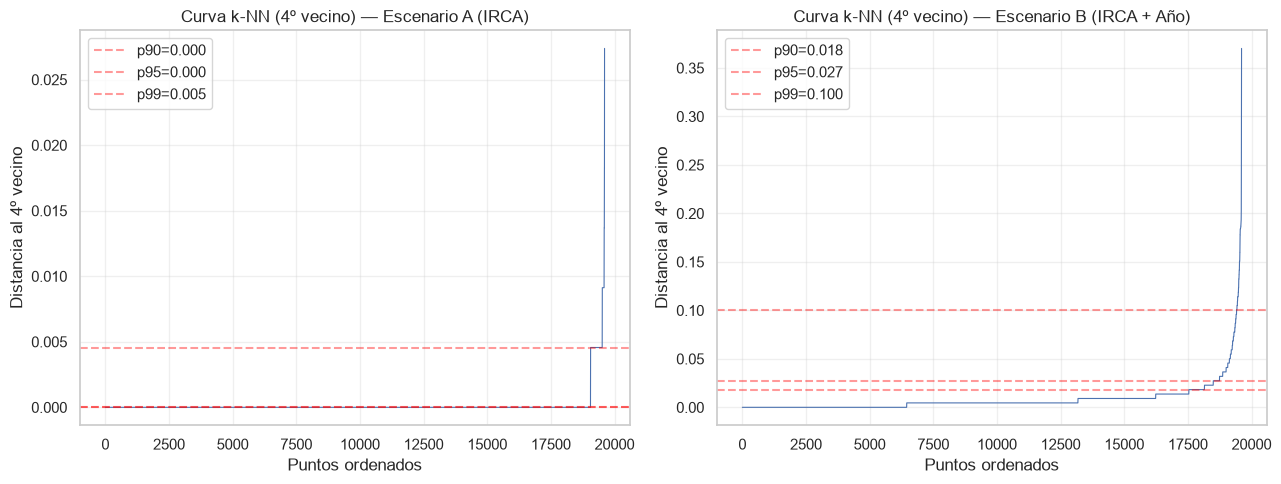

In [51]:
from sklearn.neighbors import NearestNeighbors

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (X, titulo) in zip(axes, [(X_A, "Escenario A (IRCA)"), (X_B, "Escenario B (IRCA + Año)")]):
    nn = NearestNeighbors(n_neighbors=5).fit(X)
    dist, _ = nn.kneighbors(X)
    d_k = np.sort(dist[:, -1])
    ax.plot(d_k, linewidth=0.8)
    ax.set_title(f"Curva k-NN (4º vecino) — {titulo}")
    ax.set_xlabel("Puntos ordenados")
    ax.set_ylabel("Distancia al 4º vecino")
    ax.grid(True, alpha=0.3)
    for p in [90, 95, 99]:
        ax.axhline(np.percentile(d_k, p), color="red", linestyle="--", alpha=0.4,
                   label=f"p{p}={np.percentile(d_k, p):.3f}")
    ax.legend()
plt.tight_layout()
plt.show()

In [52]:
print("Percentiles de la distancia al 4º vecino:")
for nombre, X in [("A", X_A), ("B", X_B)]:
    nn = NearestNeighbors(n_neighbors=5).fit(X)
    dist, _ = nn.kneighbors(X)
    d_k = np.sort(dist[:, -1])
    vals = "  ".join(f"p{p}={np.percentile(d_k, p):.4f}" for p in [50, 80, 90, 95, 99])
    print(f"  {nombre}: {vals}")

Percentiles de la distancia al 4º vecino:
  A: p50=0.0000  p80=0.0000  p90=0.0000  p95=0.0000  p99=0.0046
  B: p50=0.0046  p80=0.0091  p90=0.0183  p95=0.0274  p99=0.1004


**Lectura de la curva:**

- **Escenario A:** la curva es casi plana en 0 (el percentil 99 es 0.0046). El IRCA escalado
  es una variable continua **muy densa** con valores empatados, sin "valles" de densidad. No
  hay codo, lo que anticipa que DBSCAN no separará grupos naturales en 1D.
- **Escenario B:** hay un codo suave entre ~0.1 y ~0.25, pero la transición entre "sobre-
  segmentación" y "colapso" es brusca (ver barrido siguiente).

### 3.2.2 Análisis de sensibilidad de `eps` (tamaños y ruido)

Se evalúa `eps` en un rango amplio y se registra el número de clusters, el porcentaje de ruido
y la **distribución de tamaños**. El objetivo es exponer la **sensibilidad de la partición a
los cambios de `eps`**. (Nota: aquí se analiza sensibilidad paramétrica, **no** estabilidad
formal entre ejecuciones o muestras, que requeriría pruebas distintas y no se realizan.)

In [53]:
from sklearn.cluster import DBSCAN

def resumen_dbscan(X, eps, min_samples=5):
    lab = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X)
    n_clusters = len(set(lab)) - (1 if -1 in lab else 0)
    n_ruido = int((lab == -1).sum())
    tam = pd.Series(lab[lab != -1]).value_counts().sort_index()
    return n_clusters, n_ruido, tam

print("=== Escenario A (IRCA, 1D) — min_samples=5 ===")
for eps in [0.005, 0.010, 0.015, 0.020, 0.025, 0.030]:
    nc, nr, tam = resumen_dbscan(X_A, eps)
    detalle = ", ".join(f"{k}:{v}" for k, v in tam.items())
    print(f"  eps={eps:.3f}: clusters={nc}, ruido={nr} ({nr/len(X_A)*100:.2f}%) | {detalle}")

print()
print("=== Escenario B (IRCA+Año, 2D) — min_samples=5 ===")
for eps in [0.05, 0.09, 0.13, 0.15, 0.17, 0.19, 0.20, 0.21, 0.23, 0.25]:
    nc, nr, tam = resumen_dbscan(X_B, eps)
    top = ", ".join(f"{k}:{v}" for k, v in tam.head(4).items())
    extra = f" (+{tam.shape[0]-4} grupos menores)" if tam.shape[0] > 4 else ""
    print(f"  eps={eps:.3f}: clusters={nc}, ruido={nr} ({nr/len(X_B)*100:.2f}%) | {top}{extra}")

=== Escenario A (IRCA, 1D) — min_samples=5 ===


  eps=0.005: clusters=22, ruido=58 (0.30%) | 0:18995, 1:62, 2:153, 3:29, 4:8, 5:5, 6:11, 7:19, 8:43, 9:8, 10:24, 11:40, 12:11, 13:7, 14:31, 15:50, 16:6, 17:18, 18:9, 19:13, 20:5, 21:5


  eps=0.010: clusters=6, ruido=14 (0.07%) | 0:19507, 1:14, 2:12, 3:23, 4:31, 5:9


  eps=0.015: clusters=4, ruido=6 (0.03%) | 0:19531, 1:37, 2:31, 3:5


  eps=0.020: clusters=3, ruido=0 (0.00%) | 0:19575, 1:4, 2:31


  eps=0.025: clusters=3, ruido=0 (0.00%) | 0:19575, 1:4, 2:31


... (4 outputs left out)

  eps=0.200: clusters=3, ruido=5 (0.03%) | 0:19595, 1:5, 2:5


  eps=0.210: clusters=2, ruido=5 (0.03%) | 0:19600, 1:5


  eps=0.230: clusters=2, ruido=5 (0.03%) | 0:19600, 1:5


  eps=0.250: clusters=1, ruido=2 (0.01%) | 0:19608


In [54]:
print("=== Sensibilidad a min_samples (eps fijos) ===")
print("Escenario A (eps=0.02):")
for ms in [2, 3, 5, 10, 20, 50]:
    nc, nr, tam = resumen_dbscan(X_A, 0.02, ms)
    detalle = ", ".join(f"{k}:{v}" for k, v in tam.head(5).items())
    print(f"  min_samples={ms}: clusters={nc}, ruido={nr} ({nr/len(X_A)*100:.2f}%) | {detalle}")

print("Escenario B (eps=0.20):")
for ms in [3, 5, 10, 20, 50]:
    nc, nr, tam = resumen_dbscan(X_B, 0.20, ms)
    detalle = ", ".join(f"{k}:{v}" for k, v in tam.head(5).items())
    print(f"  min_samples={ms}: clusters={nc}, ruido={nr} ({nr/len(X_B)*100:.2f}%) | {detalle}")

=== Sensibilidad a min_samples (eps fijos) ===
Escenario A (eps=0.02):


  min_samples=2: clusters=2, ruido=0 (0.00%) | 0:19579, 1:31
  min_samples=3: clusters=2, ruido=0 (0.00%) | 0:19579, 1:31


  min_samples=5: clusters=3, ruido=0 (0.00%) | 0:19575, 1:4, 2:31
  min_samples=10: clusters=5, ruido=14 (0.07%) | 0:19530, 1:15, 2:10, 3:31, 4:10


  min_samples=20: clusters=5, ruido=123 (0.63%) | 0:19292, 1:103, 2:21, 3:40, 4:31
  min_samples=50: clusters=2, ruido=762 (3.89%) | 0:18768, 1:80
Escenario B (eps=0.20):


  min_samples=3: clusters=3, ruido=3 (0.02%) | 0:19597, 1:5, 2:5


  min_samples=5: clusters=3, ruido=5 (0.03%) | 0:19595, 1:5, 2:5


  min_samples=10: clusters=2, ruido=19 (0.10%) | 0:19582, 1:9


  min_samples=20: clusters=1, ruido=136 (0.69%) | 0:19474


  min_samples=50: clusters=1, ruido=667 (3.40%) | 0:18943


### Conclusión del análisis de sensibilidad

Los resultados muestran que **no existe una configuración de DBSCAN que produzca una partición
balanceada y estable**:

- **Escenario A:** cualquier `eps` da un único conglomerado masivo (≈19.500–19.610) y, a lo
  sumo, micro-clusters de decenas o unidades de puntos en el extremo superior del IRCA. La
  transición entre "22 clusters" (eps=0.005) y "1 cluster" (eps=0.030) es muy abrupta.

- **Escenario B:** la evolución con `eps` es la siguiente (con `min_samples=5`):
  - `eps=0.05` → 79 clusters (sobre-segmentación en "bandas" por año).
  - `eps` en 0.09–0.17 → disminución progresiva (45, 32, 29, 24 clusters).
  - **`eps=0.17` → 24 clusters**; **`eps=0.19` → 2 clusters**; **`eps=0.20` → 3 clusters**;
    **`eps=0.21` → 2 clusters**; `eps=0.25` → 1 cluster.

  Es decir, entre 0.17 y 0.21 la cantidad de clusters **oscila bruscamente** (24 → 2 → 3 → 2),
  y en todos estos casos el cluster mayor concentra más del 99.8% de los datos.

Esto **evidencia la limitación de DBSCAN** sobre datos con una fuerte concentración central de
la densidad y sin "valles" claros que permitan delimitar grupos. No se fuerza ninguna
configuración para obtener tres grupos ni para coincidir con K-Means: se documenta esta
limitación como resultado del experimento.

### 3.2.3 Parámetros de referencia adoptados (con fines demostrativos)

Para poder *caracterizar* el comportamiento del algoritmo se adoptan dos configuraciones de
**referencia** (no se presentan como "la solución óptima" ni como grupos representativos):

| Escenario | `eps` | `min_samples` | Resultado | Lectura |
|---|---|---|---|---|
| A (IRCA) | 0.02 | 5 | 1 masivo + 2 micro (4 y 31) | Separa micro-clusters de observaciones extremas (IRCA≈99–100) |
| B (IRCA+Año) | 0.20 | 5 | 1 masivo + 2 micro (5 y 5) + 5 ruido | Separa pequeños grupos de observaciones extremas y ruido |

Los grupos pequeños se denominan **micro-clusters de observaciones extremas**: son puntos con
IRCA muy elevado que quedan aislados del conglomerado central. **No se clasifican automáticamente
como anomalías confirmadas**; su condición de "anomalía" es solo una lectura estadística
tentativa basada en su aislamiento en el espacio de características.

Se usan para **ilustrar** el nivel de (no-)separación y para la comparación con K-Means, pero
quedan explícitamente señaladas como **no representativas** de una agrupación útil.

In [55]:
# --- Ajuste de las configuraciones de referencia ---
dbscan_A = DBSCAN(eps=0.02, min_samples=5)
dbscan_B = DBSCAN(eps=0.20, min_samples=5)

labels_A_db = dbscan_A.fit_predict(X_A)
labels_B_db = dbscan_B.fit_predict(X_B)

def reporte(labels, nombre):
    conteo = pd.Series(labels).value_counts().sort_index()
    n_noise = int((labels == -1).sum())
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    print(f"{nombre}: {n_clusters} clusters, ruido={n_noise} ({n_noise/len(labels)*100:.2f}%)")
    for k, v in conteo.items():
        etq = "RUIDO (-1)" if k == -1 else f"Cluster {k}"
        print(f"   {etq}: {v:,} ({v/len(labels)*100:.2f}%)")

reporte(labels_A_db, "Escenario A")
print()
reporte(labels_B_db, "Escenario B")

Escenario A: 3 clusters, ruido=0 (0.00%)
   Cluster 0: 19,575 (99.82%)
   Cluster 1: 4 (0.02%)
   Cluster 2: 31 (0.16%)

Escenario B: 3 clusters, ruido=5 (0.03%)
   RUIDO (-1): 5 (0.03%)
   Cluster 0: 19,595 (99.92%)
   Cluster 1: 5 (0.03%)
   Cluster 2: 5 (0.03%)


### 3.2.4 Caracterización de clusters y ruido (con metadatos)

Se unen las etiquetas con los metadatos, IRCA y Año (sin usar estas variables como entradas),
verificando la alineación fila a fila.

In [56]:
caracterizacion_db = metadatos.copy()
caracterizacion_db["IRCA"] = df_mun["IRCA"].to_numpy()
caracterizacion_db["Año"] = df_mun["Año"].to_numpy()
caracterizacion_db["cluster_A_db"] = labels_A_db
caracterizacion_db["cluster_B_db"] = labels_B_db
# etiquetas K-Means para comparación posterior
caracterizacion_db["cluster_A"] = labels_A
caracterizacion_db["cluster_B"] = labels_B

assert len(labels_A_db) == len(metadatos) and len(labels_B_db) == len(metadatos)
assert metadatos.index.equals(df_mun.index)
print("Alineación verificada:", len(metadatos), "filas para metadatos, IRCA, Año y etiquetas.")

Alineación verificada: 19610 filas para metadatos, IRCA, Año y etiquetas.


In [57]:
print("===== ESCENARIO A (IRCA) — perfil por cluster =====")
for c in np.unique(labels_A_db):
    sub = caracterizacion_db[caracterizacion_db["cluster_A_db"] == c]
    nombre = "RUIDO (-1)" if c == -1 else f"Cluster {c}"
    print(f"\n{nombre} (n={len(sub):,}):")
    print(f"  IRCA: media={sub['IRCA'].mean():.2f}, mediana={sub['IRCA'].median():.2f}, "
          f"min={sub['IRCA'].min():.2f}, max={sub['IRCA'].max():.2f}")

===== ESCENARIO A (IRCA) — perfil por cluster =====

Cluster 0 (n=19,575):
  IRCA: media=20.56, mediana=12.20, min=0.00, max=98.70

Cluster 1 (n=4):
  IRCA: media=99.22, mediana=99.25, min=99.00, max=99.40

Cluster 2 (n=31):
  IRCA: media=100.00, mediana=100.00, min=100.00, max=100.00


In [58]:
print("===== ESCENARIO B (IRCA + Año) — perfil por cluster =====")
for c in np.unique(labels_B_db):
    sub = caracterizacion_db[caracterizacion_db["cluster_B_db"] == c]
    nombre = "RUIDO (-1)" if c == -1 else f"Cluster {c}"
    print(f"\n{nombre} (n={len(sub):,}):")
    print(f"  IRCA: media={sub['IRCA'].mean():.2f}, mediana={sub['IRCA'].median():.2f}, "
          f"min={sub['IRCA'].min():.2f}, max={sub['IRCA'].max():.2f}")
    print(f"  Año: media={sub['Año'].mean():.2f}, min={sub['Año'].min()}, max={sub['Año'].max()}")

===== ESCENARIO B (IRCA + Año) — perfil por cluster =====

RUIDO (-1) (n=5):
  IRCA: media=93.20, mediana=96.60, min=84.20, max=100.00
  Año: media=2022.60, min=2020, max=2025

Cluster 0 (n=19,595):
  IRCA: media=20.65, mediana=12.20, min=0.00, max=100.00
  Año: media=2015.94, min=2007, max=2025

Cluster 1 (n=5):
  IRCA: media=95.78, mediana=96.50, min=93.60, max=97.90
  Año: media=2024.00, min=2023, max=2025

Cluster 2 (n=5):
  IRCA: media=99.86, mediana=100.00, min=99.30, max=100.00
  Año: media=2011.20, min=2011, max=2012


### 3.2.5 Consistencia de la categoría «Inviable sanitariamente» frente a IRCA ≥ 80

Antes de interpretar los extremos, se verifica la **coherencia** entre la variable numérica
`IRCA` y la categoría `Nivel de riesgo`, en particular en el límite superior de la escala.

In [59]:
# --- Contraste entre la categoría y el umbral numérico ---
n_inviable = (df_mun["Nivel de riesgo"] == "Inviable sanitariamente").sum()
n_irka80 = (df_mun["IRCA"] >= 80).sum()

print(f'Categoría "Inviable sanitariamente": {n_inviable}')
print(f"Registros con IRCA >= 80:           {n_irka80}")
print(f"Diferencia:                         {n_irka80 - n_inviable}")
print()

# Registros con IRCA >= 80 que NO son "Inviable"
sub80_noinv = df_mun[(df_mun["IRCA"] >= 80) & (df_mun["Nivel de riesgo"] != "Inviable sanitariamente")]
print("Registros IRCA>=80 clasificados con otra categoría:")
print(sub80_noinv[["IRCA", "Nivel de riesgo"]].value_counts().to_string())
print()
print("Rango de IRCA de la categoría 'Inviable sanitariamente':")
inv = df_mun[df_mun["Nivel de riesgo"] == "Inviable sanitariamente"]["IRCA"]
print(f"  min={inv.min():.2f}, max={inv.max():.2f}, media={inv.mean():.2f}")

# Rangos normativos de cada categoría
print()
print("Rangos de IRCA por categoría (observados):")
for nivel in sorted(df_mun["Nivel de riesgo"].unique()):
    s = df_mun[df_mun["Nivel de riesgo"] == nivel]["IRCA"]
    print(f"  {nivel:28s}: n={len(s):5d}  IRCA [{s.min():.2f}, {s.max():.2f}]")

Categoría "Inviable sanitariamente": 358
Registros con IRCA >= 80:           364
Diferencia:                         6

Registros IRCA>=80 clasificados con otra categoría:
IRCA    Nivel de riesgo
80.000  Riesgo alto        6

Rango de IRCA de la categoría 'Inviable sanitariamente':
  min=80.10, max=100.00, media=88.54

Rangos de IRCA por categoría (observados):
  Alto riesgo                 : n=   65  IRCA [35.10, 79.00]
  Bajo riesgo                 : n=  256  IRCA [5.10, 14.00]
  Inviable sanitariamente     : n=  358  IRCA [80.10, 100.00]
  Riesgo alto                 : n= 4178  IRCA [35.10, 80.00]
  Riesgo bajo                 : n= 3774  IRCA [5.10, 14.00]
  Riesgo medio                : n= 4604  IRCA [14.10, 35.00]
  Sin riesgo                  : n= 6375  IRCA [0.00, 5.00]


**Resultado:** la diferencia entre 358 («Inviable») y 364 (IRCA ≥ 80) se debe a **6 registros
con IRCA exactamente igual a 80.0** que el portal clasifica como «Riesgo alto» (no «Inviable»).

Esto es coherente con la **escala normativa** (Resolución 2115 de 2007, MSPS):

- «Riesgo alto»: IRCA de 35.1 a 80.0.
- «Inviable sanitariamente»: IRCA **> 80.0** (en la práctica, 80.1 a 100).

Es decir, el valor **80.0 exacto es un punto frontera**: con la regla «mayor estricto» cae en
«Riesgo alto», y por eso la categoría «Inviable» comienza en 80.1. No hay, por tanto,
inconsistencia grave: es una característica del umbral de corte (el valor 80.0 queda en el
intervalo superior de «Riesgo alto»).

> Además, recuérdese la existencia de **dos convenciones de etiquetas** (documentada en la
> Etapa 2): «Sin riesgo/Riesgo bajo/Riesgo medio/Riesgo alto» (antigua) y
> «Bajo riesgo/Riesgo medio/Riesgo alto/Inviable sanitariamente» (actual), cuyas fronteras
> numéricas difieren ligeramente en la etiqueta del límite inferior.

### 3.2.6 Distinción entre riesgo sanitario y anomalía estadística

Es fundamental **no confundir** dos conceptos distintos:

- **Riesgo sanitario** (categoría normativa): un municipio con IRCA ≥ 80 (sin o con nivel
  «Inviable sanitariamente») tiene, según la escala oficial, un riesgo *administrativo* de
  calidad del agua. Son **364** municipios-año en este nivel.

- **Anomalía estadística (potencial)** (ruido de DBSCAN): un punto que, por su posición en el
  espacio de características, queda **aislado de la densidad** del resto. DBSCAN NO identifica
  «todos los municipios de alto riesgo»; sólo marca como ruido **5 observaciones** que, además
  de ser muy altas en IRCA, están *alejadas* del grueso de los datos en el espacio IRCA×Año.

  > El etiquetado como "ruido" es una **lectura basada en densidad**, no una confirmación
  > externa de que la observación sea errónea o anómala en sentido real. Se trata de puntos
  > estadísticamente aislados, que pueden ser legítimos (riesgo sanitario realmente extremo).

DBSCAN detecta un **subconjunto muy reducido** de los extremos, no la totalidad del riesgo
sanitario. La mayoría de los IRCA ≥ 80 residen en la vecindad de otros puntos altos y, por
tanto, NO son ruido.

In [60]:
# --- Riesgo sanitario vs anomalía: cuántos IRCA>=80 son marcados como ruido ---
mask80 = caracterizacion_db["IRCA"] >= 80
print(f"IRCA >= 80 total (riesgo sanitario alto): {mask80.sum()}")

for nombre, col in [("A", "cluster_A_db"), ("B", "cluster_B_db")]:
    sub_ruido = caracterizacion_db[caracterizacion_db[col] == -1]
    n80_ruido = (sub_ruido["IRCA"] >= 80).sum()
    print(f"\nEscenario {nombre}:")
    print(f"  Ruido DBSCAN total: {len(sub_ruido)}")
    print(f"  De esos, con IRCA>=80 (anomalías de alto riesgo): {n80_ruido}")
    print(f"  Porcentaje de IRCA>=80 que DBSCAN marca como ruido: "
          f"{n80_ruido/mask80.sum()*100:.1f}%")

IRCA >= 80 total (riesgo sanitario alto): 364

Escenario A:
  Ruido DBSCAN total: 0
  De esos, con IRCA>=80 (anomalías de alto riesgo): 0
  Porcentaje de IRCA>=80 que DBSCAN marca como ruido: 0.0%

Escenario B:
  Ruido DBSCAN total: 5
  De esos, con IRCA>=80 (anomalías de alto riesgo): 5
  Porcentaje de IRCA>=80 que DBSCAN marca como ruido: 1.4%


### 3.2.7 Visualizaciones

Se resaltan el ruido y los micro-clusters extremos para evidenciar el comportamiento de
DBSCAN.

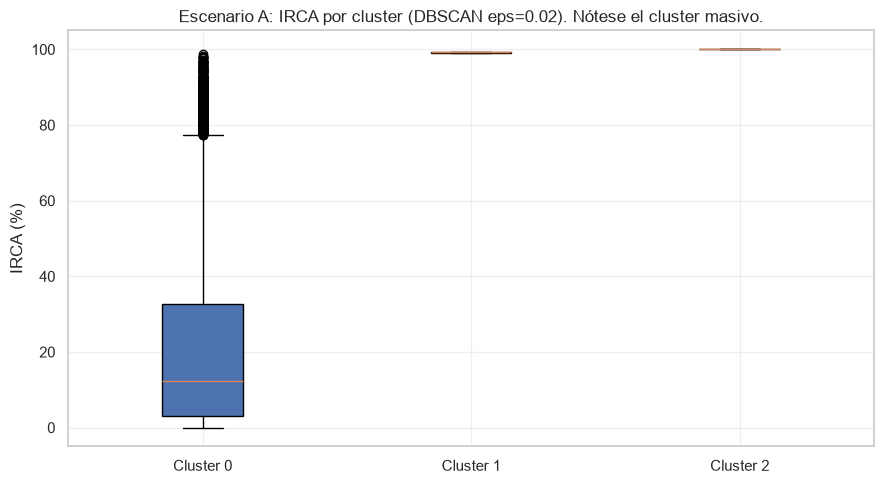

In [61]:
# --- Escenario A: boxplot del IRCA por cluster (DBSCAN) ---
fig, ax = plt.subplots(figsize=(9, 5))
grupos_A = [caracterizacion_db[caracterizacion_db["cluster_A_db"] == c]["IRCA"]
            for c in np.unique(labels_A_db)]
nombres_A = ["Ruido (-1)" if c == -1 else f"Cluster {c}" for c in np.unique(labels_A_db)]
ax.boxplot(grupos_A, patch_artist=True)
ax.set_xticklabels(nombres_A)
ax.set_title("Escenario A: IRCA por cluster (DBSCAN eps=0.02). Nótese el cluster masivo.")
ax.set_ylabel("IRCA (%)")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

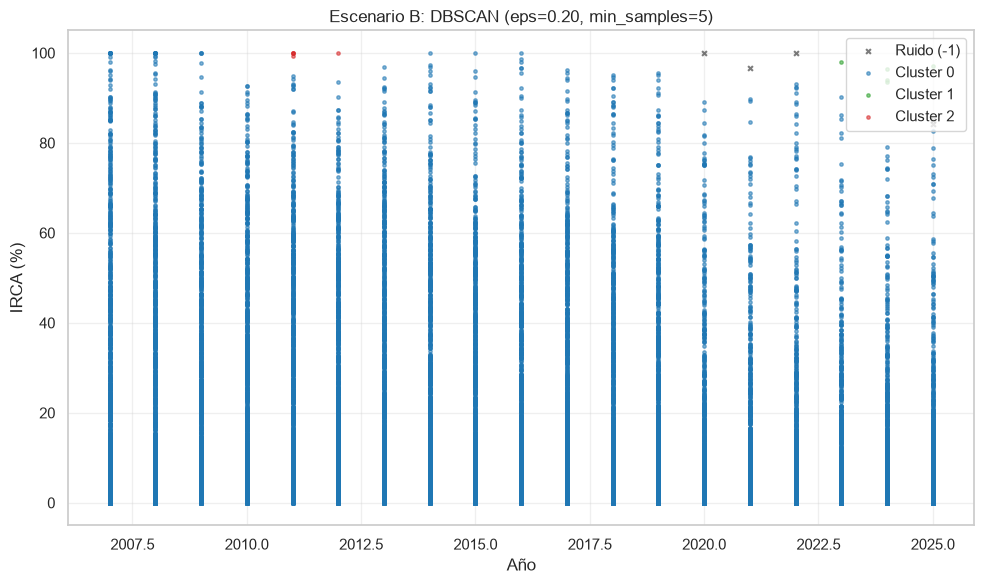

In [62]:
# --- Escenario B: dispersión IRCA vs Año (DBSCAN) ---
fig, ax = plt.subplots(figsize=(10, 6))
paleta = {0: "#1f77b4", 1: "#2ca02c", 2: "#d62728", -1: "#111111"}
for c in np.unique(labels_B_db):
    sub = caracterizacion_db[caracterizacion_db["cluster_B_db"] == c]
    etq = "Ruido (-1)" if c == -1 else f"Cluster {c}"
    ax.scatter(sub["Año"], sub["IRCA"], s=12 if c == -1 else 6, alpha=0.55,
               color=paleta.get(c, "#888"), marker="x" if c == -1 else "o", label=etq)
ax.set_title("Escenario B: DBSCAN (eps=0.20, min_samples=5)")
ax.set_xlabel("Año")
ax.set_ylabel("IRCA (%)")
ax.legend(markerscale=1.0)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 3.2.8 Métricas de evaluación y sus limitaciones

El **coeficiente de silueta** es una **métrica descriptiva** que aquí debe interpretarse con
prudencia, por dos razones:

1. **Solo se calcula sobre los puntos asignados a clusters** (se excluye el ruido, que no
   pertenece a ningún grupo). Por tanto, no refleja el comportamiento completo de DBSCAN, sino
   únicamente la compacidad/separación de los puntos efectivamente agrupados.
2. Ante un **desbalance extremo** (un cluster masivo + micro-clusters de 4–31 puntos), el valor
   global de la silueta está dominado por el conglomerado mayor y puede resultar artificialmente
   aceptable, sin que ello signifique que la partición sea útil.

- Un cluster masivo "absorbe" la mayor parte de los puntos y la silueta global puede resultar
  artificialmente aceptable porque la mayoría de puntos comparten el mismo grupo.
- La silueta de los micro-clusters (4–31 puntos) es poco representativa.
- Si solo hay 1 cluster, o casi todo es ruido, la silueta **no aplica**.

En consecuencia, los valores reportados se conservan como **referencia descriptiva**, no como
evidencia de calidad de la partición.

In [63]:
from sklearn.metrics import silhouette_score

def silueta_dbscan(X, labels, nombre):
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    mask = labels != -1
    if n_clusters < 2 or mask.sum() < 2 or len(set(labels[mask])) < 2:
        print(f"{nombre}: silueta NO aplicable ({n_clusters} cluster(s)).")
        return None
    s = silhouette_score(X[mask], labels[mask])
    print(f"{nombre}: silueta (excluyendo ruido) = {s:.4f}  [advertencia: grupos muy desbalanceados]")
    return s

s_A = silueta_dbscan(X_A, labels_A_db, "Escenario A")
s_B = silueta_dbscan(X_B, labels_B_db, "Escenario B")

Escenario A: silueta (excluyendo ruido) = 0.6368  [advertencia: grupos muy desbalanceados]


Escenario B: silueta (excluyendo ruido) = 0.4554  [advertencia: grupos muy desbalanceados]


### 3.2.9 Comparación con K-Means (y conclusión sobre IRCA ≥ 80)

Se compara cómo K-Means y DBSCAN tratan las observaciones extremas (IRCA ≥ 80).

In [64]:
mask80 = caracterizacion_db["IRCA"] >= 80
print(f"IRCA >= 80: {mask80.sum()} registros")
print()
print("Escenario A — distribución de IRCA>=80 por método:")
print("  K-Means (K=3):    ", caracterizacion_db[mask80]["cluster_A"].value_counts().to_dict())
print("  DBSCAN (eps=0.02):", caracterizacion_db[mask80]["cluster_A_db"].value_counts().to_dict())
print()
print("Escenario B — distribución de IRCA>=80 por método:")
print("  K-Means (K=3):    ", caracterizacion_db[mask80]["cluster_B"].value_counts().to_dict())
print("  DBSCAN (eps=0.20):", caracterizacion_db[mask80]["cluster_B_db"].value_counts().to_dict())

IRCA >= 80: 364 registros

Escenario A — distribución de IRCA>=80 por método:
  K-Means (K=3):     {2: 364}
  DBSCAN (eps=0.02): {0: 329, 2: 31, 1: 4}

Escenario B — distribución de IRCA>=80 por método:
  K-Means (K=3):     {0: 364}
  DBSCAN (eps=0.20): {0: 349, 1: 5, 2: 5, -1: 5}


**Lectura correcta de la comparación:**

- **K-Means** asigna todos los IRCA ≥ 80 a un mismo cluster (el de mayor riesgo), porque no
  distingue anomalías: todo punto pertenece a *algún* cluster.

- **DBSCAN** separa solo un **puñado** de extremos (5 ruido en B; micro-clusters de 4 y 31 en
  A). La mayoría de los IRCA ≥ 80 siguen dentro del conglomerado masivo porque están rodeados
  de otros puntos altos.

**Conclusión:** DBSCAN no identifica "todos los municipios de alto riesgo" — eso lo hace la
categoría normativa. DBSCAN identifica un número **mínimo** de observaciones estadísticamente
anómalas (aisladas en densidad). Ambos conceptos son complementarios, no equivalentes.

### 3.2.10 Limitaciones, decisiones y conclusión de la subetapa

**Limitaciones observadas (resultado del experimento):**

1. **DBSCAN no produjo agrupaciones representativas.** En ambos escenarios, la partición es
   "un conglomerado dominante + micro-clusters/ruido", sin grupos balanceados.
2. **La densidad presenta una fuerte concentración central** (muchos valores cercanos entre sí
   y una distribución continua) que dificulta la identificación de "valles" que DBSCAN pueda
   explotar. No se afirma uniformidad: solo se describe la concentración observada.
3. **La sensibilidad a `eps` es muy alta:** en el Escenario A se pasa de 22 clusters (eps=0.005)
   a 1 (eps=0.03); en B, la cantidad de clusters oscila de forma abrupta entre 24 (0.17), 2
   (0.19), 3 (0.20) y 2 (0.21). Esta es una **sensibilidad paramétrica**, distinta de la
   *estabilidad* formal del algoritmo (que no se evaluó con pruebas de remuestreo o múltiples
   ejecuciones con distintas semillas).

**Decisiones metodológicas:**

- No se forzó ninguna configuración para obtener "tres grupos" ni para coincidir con K-Means.
- Se conservan dos configuraciones **de referencia** (A: eps=0.02, B: eps=0.20) únicamente para
  ilustrar el comportamiento y permitir la comparación, marcadas como no-representativas.
- `min_samples=5` se fijó como criterio estricto de densidad (≥ dim+1).
- La silueta se reporta como métrica descriptiva, calculada solo sobre puntos asignados y con
  advertencia por desbalance extremo.

**Conclusión:** DBSCAN **no es un algoritmo adecuado** para encontrar grupos en este conjunto
de datos (fuerte concentración central de la densidad, sin separaciones claras). Su utilidad
residual es la **identificación tentativa de un reducido subconjunto de observaciones aisladas**
en el extremo alto del IRCA, que no deben confundirse con la totalidad del riesgo sanitario.
Esta conclusión se documenta como hallazgo metodológico y no se distorsiona el resultado para
presentar una agrupación que no existe.

### 3.2.11 Guardado de resultados de DBSCAN

Se guardan modelos, etiquetas, parámetros y resultados para trazabilidad y comparación.

In [65]:
resultados_dbscan = {
    "labels_A": labels_A_db,
    "labels_B": labels_B_db,
    "dbscan_A": dbscan_A,
    "dbscan_B": dbscan_B,
    "eps_A": 0.02,
    "eps_B": 0.20,
    "min_samples": 5,
    "sil_A_db": s_A,
    "sil_B_db": s_B,
    "caracterizacion_db": caracterizacion_db,
    "n_inviable": int((df_mun["Nivel de riesgo"] == "Inviable sanitariamente").sum()),
    "n_irka80": int((df_mun["IRCA"] >= 80).sum()),
}

with open("data_etapa3_dbscan.pkl", "wb") as f:
    pickle.dump(resultados_dbscan, f)

print("Resultados de DBSCAN guardados en: data_etapa3_dbscan.pkl")
print()
print("Subetapa 3.2 (DBSCAN) revisada y completada.")
print("Conclusión: DBSCAN no produce agrupaciones representativas; se documenta como limitación.")

Resultados de DBSCAN guardados en: data_etapa3_dbscan.pkl

Subetapa 3.2 (DBSCAN) revisada y completada.
Conclusión: DBSCAN no produce agrupaciones representativas; se documenta como limitación.


---
## 3.3 Clustering jerárquico

### 3.3.1 Justificación del uso del clustering jerárquico

El **clustering jerárquico aglomerativo** construye una **jerarquía de agrupamientos** (un
dendrograma) fusionando iterativamente los puntos/agrupaciones más cercanos según un **criterio
de enlace**. Se elige como tercer algoritmo porque:

- **No exige** especificar el número de clusters *a priori*: la jerarquía permite *inspeccionar*
  diferentes cortes (k) después de una única construcción.
- Ofrece un **dendrograma** que aporta una visión estructural de las relaciones (a diferencia de
  K-Means, que solo devuelve una partición plana).
- Es **determinista** y reproducible (no depende de inicialización aleatoria como K-Means).
- Complementa a K-Means (partición "plana") y a DBSCAN (basado en densidad) con una perspectiva
  **jerárquica/anidada** de la estructura de los datos del IRCA.

### Viabilidad computacional

Con ~19.610 observaciones, la matriz condensada de distancias ocupa ≈1.5 GB y el algoritmo de
aglomeración (implementación de `scipy.cluster.hierarchy.linkage`) corre en pocos segundos
(6–20 s según el método). Es, por tanto, **viable aplicar el método al conjunto completo**, sin
necesidad de submuestrear el algoritmo (el submuestreo se reserva **exclusivamente** para la
visualización del dendrograma, que con 19.610 hojas sería ilegible).

### 3.3.2 Análisis de los métodos de enlace

| Método | Idea | Comportamiento esperado | Viabilidad (n≈19.610) |
|---|---|---|---|
| **Ward** | Minimiza la varianza intra-cluster (inercia) | Grupos compactos y esféricos | Viable (~20 s) |
| **Complete** | Distancia máxima entre puntos | Grupos compactos, evita "cadenas" | Viable (~15 s) |
| **Average** | Distancia media entre puntos | Compromiso, grupos razonables | Viable (~16 s) |
| **Single** | Distancia mínima entre puntos | Tiende a formar "cadenas" (encadenamiento) | Viable (~6.5 s) |

**Criterio de elección:**

- El método **single** es propenso al *encadenamiento* (une un punto a un grupo si un solo par
  está cerca), lo que produce clusters alargados poco útiles para variables continuas densas.
- **Ward**, que minimiza la suma de cuadrados intra-cluster, tiende a producir grupos
  **compactos**, y es coherente con la métrica euclidiana y con el escalado `StandardScaler`
  aplicado.

> **Nota sobre el tamaño de los grupos:** Ward favorece la *minimización de la varianza
> intra-cluster*, pero **no garantiza tamaños equilibrados**. El que los grupos resultantes sean
> balanceados es un resultado *observado* en este conjunto (véase §3.3.6), no una propiedad del
> método. Se selecciona **Ward** como método principal.

Se documentan los tiempos de ejecución reales para demostrar la viabilidad.

In [66]:
# --- Importaciones de clustering jerárquico ---
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy.cluster import hierarchy

import time

# --- Verificación de viabilidad: tiempo de cada método de enlace ---
resultados_enlace = {}
for method in ['ward', 'complete', 'average', 'single']:
    t = time.time()
    Z_tmp = linkage(X_B, method=method)   # X_B (2D) como prueba representativa
    dt = time.time() - t
    resultados_enlace[method] = round(dt, 2)
    print(f"Enlace '{method}': {dt:.2f} s, {Z_tmp.shape[0]} fusiones")

print()
print("n observaciones:", len(X_A))
print("Memoria matriz condensada (est.): {:.2f} GB".format(
    (len(X_A) * (len(X_A) - 1) / 2 * 8) / 1e9))

Enlace 'ward': 17.89 s, 19609 fusiones


Enlace 'complete': 14.39 s, 19609 fusiones


Enlace 'average': 15.19 s, 19609 fusiones


Enlace 'single': 6.28 s, 19609 fusiones

n observaciones: 19610
Memoria matriz condensada (est.): 1.54 GB


### 3.3.3 Construcción de la jerarquía (método Ward) sobre el conjunto completo

Se aplica el linkage **una sola vez por escenario** sobre las 19.610 observaciones. A partir de
esta jerarquía se pueden extraer distintos cortes (k) sin reconstruir el modelo.

In [67]:
# --- Linkage (Ward) sobre el conjunto COMPLETO (19.610 obs) ---
t0 = time.time()
Z_A = linkage(X_A, method='ward')
t_A = time.time() - t0

t0 = time.time()
Z_B = linkage(X_B, method='ward')
t_B = time.time() - t0

print(f"Linkage Ward Escenario A: {t_A:.2f} s, {Z_A.shape[0]} fusiones")
print(f"Linkage Ward Escenario B: {t_B:.2f} s, {Z_B.shape[0]} fusiones")

Linkage Ward Escenario A: 4.98 s, 19609 fusiones
Linkage Ward Escenario B: 17.85 s, 19609 fusiones


### 3.3.4 Dendrograma (truncado) para visualización

Con 19.610 observaciones, el dendrograma completo es **ilegible**. Se usa la opción
`truncate_mode='lastp'` de `scipy`, que **colapsa** las últimas hojas en un número limitado de
ramas (p. ej. 20–40), conservando la **estructura de los niveles superiores**.

> **Distinción importante:** el *dendrograma truncado* es **solo una herramienta de
> visualización**. La aplicación del algoritmo (el linkage) se realizó sobre el **conjunto
> completo**, no sobre una muestra.

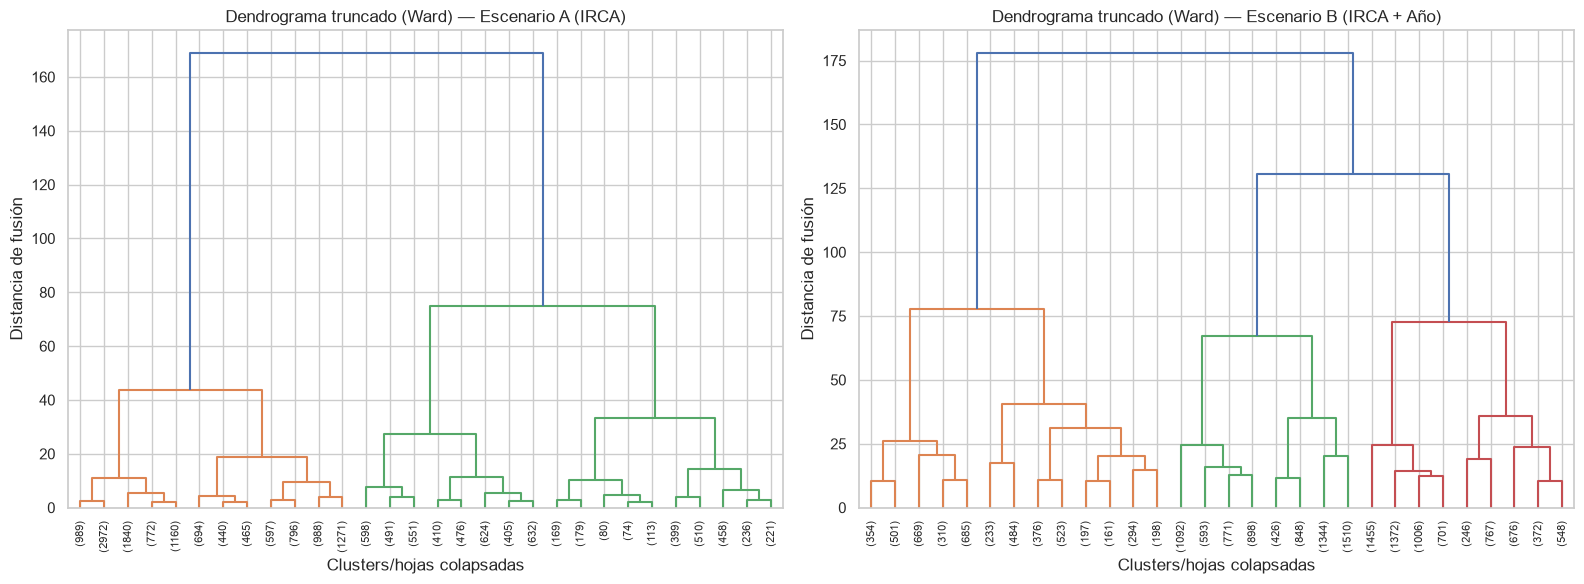

In [68]:
# --- Dendrograma truncado (lastp=30) para ambos escenarios ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, (Z, titulo) in zip(axes, [(Z_A, "Escenario A (IRCA)"), (Z_B, "Escenario B (IRCA + Año)")]):
    dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90., leaf_font_size=8, ax=ax)
    ax.set_title(f"Dendrograma truncado (Ward) — {titulo}")
    ax.set_xlabel("Clusters/hojas colapsadas")
    ax.set_ylabel("Distancia de fusión")

plt.tight_layout()
plt.show()

### 3.3.5 Evaluación del número de clusters (sin imponer una solución)

Se calculan **tres métricas** para distintos cortes `k`, sin presuponer que tres grupos es la
mejor opción:

- **Silhouette** (mayor = mejor; -1 a 1).
- **Davies-Bouldin** (menor = mejor).
- **Calinski-Harabasz** (mayor = mejor; sensible al número de clusters).

In [69]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

kvals = [2, 3, 4, 5, 6, 7, 8]

def evaluar_k(Z, X, kvals):
    res = {"k": [], "silhouette": [], "db": [], "ch": []}
    for k in kvals:
        labels = fcluster(Z, k, criterion='maxclust')
        res["k"].append(k)
        res["silhouette"].append(silhouette_score(X, labels))
        res["db"].append(davies_bouldin_score(X, labels))
        res["ch"].append(calinski_harabasz_score(X, labels))
    return pd.DataFrame(res)

tabla_A = evaluar_k(Z_A, X_A, kvals)
tabla_B = evaluar_k(Z_B, X_B, kvals)

print("Escenario A:")
print(tabla_A.round(4).to_string(index=False))
print()
print("Escenario B:")
print(tabla_B.round(4).to_string(index=False))

Escenario A:
 k  silhouette    db         ch
 2       0.673 0.501  52114.503
 3       0.639 0.521  65388.730
 4       0.582 0.534  73088.405
 5       0.577 0.502  85926.053
 6       0.578 0.510 108816.430
 7       0.564 0.506 123614.344
 8       0.562 0.505 134156.475

Escenario B:
 k  silhouette    db        ch
 2       0.411 0.952 13259.053
 3       0.377 0.897 16051.587
 4       0.341 0.898 15078.203
 5       0.342 0.862 15942.928
 6       0.371 0.889 18189.401
 7       0.366 0.900 17601.359
 8       0.351 0.969 17178.092


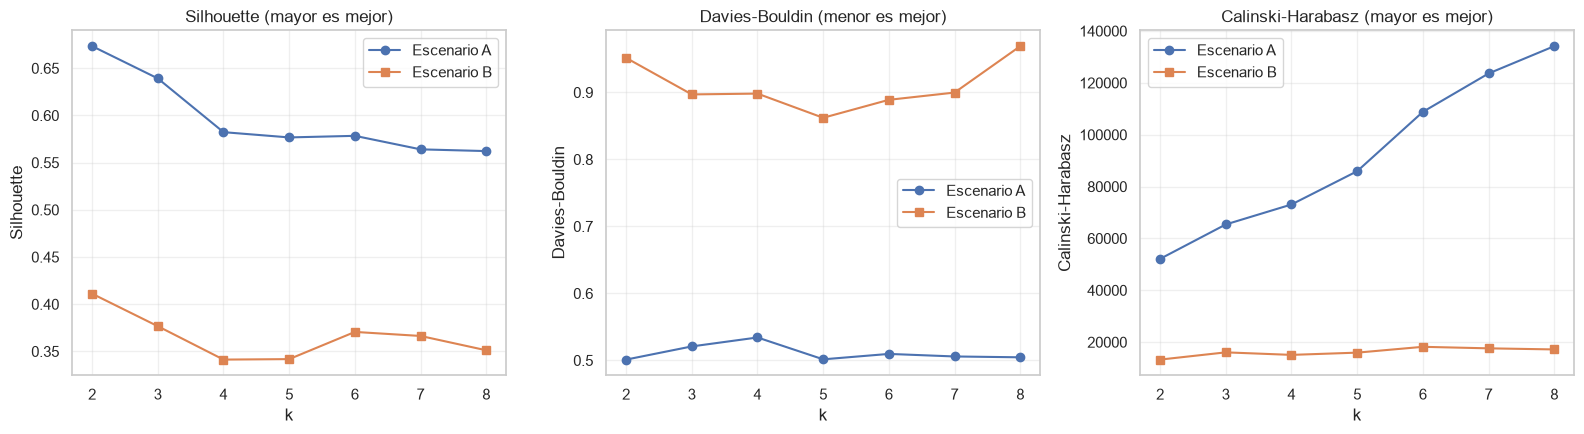

In [70]:
# --- Visualización de las métricas vs k (tres paneles: A y B en cada uno) ---
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Panel 1: Silhouette (mayor es mejor)
axes[0].plot(tabla_A["k"], tabla_A["silhouette"], marker="o", label="Escenario A")
axes[0].plot(tabla_B["k"], tabla_B["silhouette"], marker="s", label="Escenario B")
axes[0].set_title("Silhouette (mayor es mejor)")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Silhouette")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Panel 2: Davies-Bouldin (menor es mejor)
axes[1].plot(tabla_A["k"], tabla_A["db"], marker="o", label="Escenario A")
axes[1].plot(tabla_B["k"], tabla_B["db"], marker="s", label="Escenario B")
axes[1].set_title("Davies-Bouldin (menor es mejor)")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Davies-Bouldin")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Panel 3: Calinski-Harabasz (mayor es mejor)
axes[2].plot(tabla_A["k"], tabla_A["ch"], marker="o", label="Escenario A")
axes[2].plot(tabla_B["k"], tabla_B["ch"], marker="s", label="Escenario B")
axes[2].set_title("Calinski-Harabasz (mayor es mejor)")
axes[2].set_xlabel("k")
axes[2].set_ylabel("Calinski-Harabasz")
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Interpretación de las métricas

Los resultados de las tres métricas **no son unánimes**:

- **Silhouette** favorece **k=2** en ambos escenarios (A: 0.673; B: 0.411).
- **Davies-Bouldin** favorece **k=2** en el Escenario A (0.501) y **k=5** en el Escenario B
  (0.862).
- **Calinski-Harabasz** alcanza su máximo en **k=8** para el Escenario A (134.156) y en **k=6**
  para el Escenario B (18.189). Como CH tiende a crecer con el número de clusters, su máximo no
  es un criterio fiable por sí solo para elegir k.

**Decisión transparente (k=2 como principal):** ante la **falta de consenso entre métricas**, se
adopta **k=2** como configuración principal **priorizando la silueta** (única métrica que
coincide en ambos escenarios apuntando a k=2) y el criterio de **simplicidad/parsimonia** (menor
número de grupos, divisiones más estables). Se deja explícito que esta elección **no** es
respaldada por todas las métricas y que k=3 se reporta como alternativa interpretativa, sin
presentarlo como "mejor" ni forzarlo para parecerse a K-Means.

### 3.3.6 Aplicación del método seleccionado (Ward) a ambos escenarios

Se extraen las particiones para **k=2** (principal) y **k=3** (alternativa) mediante
`fcluster` con `criterion='maxclust'`.

In [71]:
# --- Cortes en la jerarquía ---
labels_A_j2 = fcluster(Z_A, 2, criterion='maxclust')
labels_B_j2 = fcluster(Z_B, 2, criterion='maxclust')
labels_A_j3 = fcluster(Z_A, 3, criterion='maxclust')
labels_B_j3 = fcluster(Z_B, 3, criterion='maxclust')

def reporte_tam(labels, nombre):
    tam = pd.Series(labels).value_counts().sort_index()
    print(f"{nombre}:")
    for k, v in tam.items():
        print(f"   Cluster {k}: {v:,} ({v/len(labels)*100:.1f}%)")

reporte_tam(labels_A_j2, "Escenario A, k=2")
print()
reporte_tam(labels_B_j2, "Escenario B, k=2")
print()
reporte_tam(labels_A_j3, "Escenario A, k=3")
print()
reporte_tam(labels_B_j3, "Escenario B, k=3")

Escenario A, k=2:
   Cluster 1: 12,984 (66.2%)
   Cluster 2: 6,626 (33.8%)

Escenario B, k=2:
   Cluster 1: 4,985 (25.4%)
   Cluster 2: 14,625 (74.6%)

Escenario A, k=3:
   Cluster 1: 12,984 (66.2%)
   Cluster 2: 4,187 (21.4%)
   Cluster 3: 2,439 (12.4%)

Escenario B, k=3:
   Cluster 1: 4,985 (25.4%)
   Cluster 2: 7,482 (38.2%)
   Cluster 3: 7,143 (36.4%)


### 3.3.7 Caracterización de los grupos con metadatos y variables originales

Se unen las etiquetas con los **metadatos** y el IRCA/Año en escala original, verificando la
alineación, para interpretar los grupos (sin incorporar estas variables al entrenamiento).

In [72]:
# --- Caracterización (alineación verificada) ---
caract_jer = metadatos.copy()
caract_jer["IRCA"] = df_mun["IRCA"].to_numpy()
caract_jer["Año"] = df_mun["Año"].to_numpy()
caract_jer["j_A_2"] = labels_A_j2
caract_jer["j_A_3"] = labels_A_j3
caract_jer["j_B_2"] = labels_B_j2
caract_jer["j_B_3"] = labels_B_j3

assert len(labels_A_j2) == len(metadatos) == len(df_mun)
assert metadatos.index.equals(df_mun.index)
print("Alineación verificada:", len(metadatos), "filas.")

Alineación verificada: 19610 filas.


In [73]:
# --- Perfil de los grupos (k=2 y k=3) ---
for nombre_col, titulo in [("j_A_2", "Escenario A (k=2)"), ("j_A_3", "Escenario A (k=3)"),
                           ("j_B_2", "Escenario B (k=2)"), ("j_B_3", "Escenario B (k=3)")]:
    print(f"===== {titulo} =====")
    for c in sorted(set(caract_jer[nombre_col])):
        sub = caract_jer[caract_jer[nombre_col] == c]
        print(f"  Cluster {c}: n={len(sub):,} | IRCA media={sub['IRCA'].mean():.2f} "
              f"(min={sub['IRCA'].min():.2f}, max={sub['IRCA'].max():.2f}) | "
              f"Año media={sub['Año'].mean():.2f}")
    print()

===== Escenario A (k=2) =====
  Cluster 1: n=12,984 | IRCA media=7.36 (min=0.00, max=24.00) | Año media=2016.98
  Cluster 2: n=6,626 | IRCA media=46.85 (min=24.10, max=100.00) | Año media=2013.93

===== Escenario A (k=3) =====
  Cluster 1: n=12,984 | IRCA media=7.36 (min=0.00, max=24.00) | Año media=2016.98
  Cluster 2: n=4,187 | IRCA media=35.97 (min=24.10, max=50.20) | Año media=2014.25
  Cluster 3: n=2,439 | IRCA media=65.53 (min=50.30, max=100.00) | Año media=2013.37

===== Escenario B (k=2) =====
  Cluster 1: n=4,985 | IRCA media=49.06 (min=14.50, max=100.00) | Año media=2011.42
  Cluster 2: n=14,625 | IRCA media=11.04 (min=0.00, max=58.80) | Año media=2017.49

===== Escenario B (k=3) =====
  Cluster 1: n=4,985 | IRCA media=49.06 (min=14.50, max=100.00) | Año media=2011.42
  Cluster 2: n=7,482 | IRCA media=8.25 (min=0.00, max=38.60) | Año media=2013.49
  Cluster 3: n=7,143 | IRCA media=13.96 (min=0.00, max=58.80) | Año media=2021.68



### 3.3.8 Visualizaciones

Se representan los grupos (k=2 principal) en el espacio original de cada escenario.

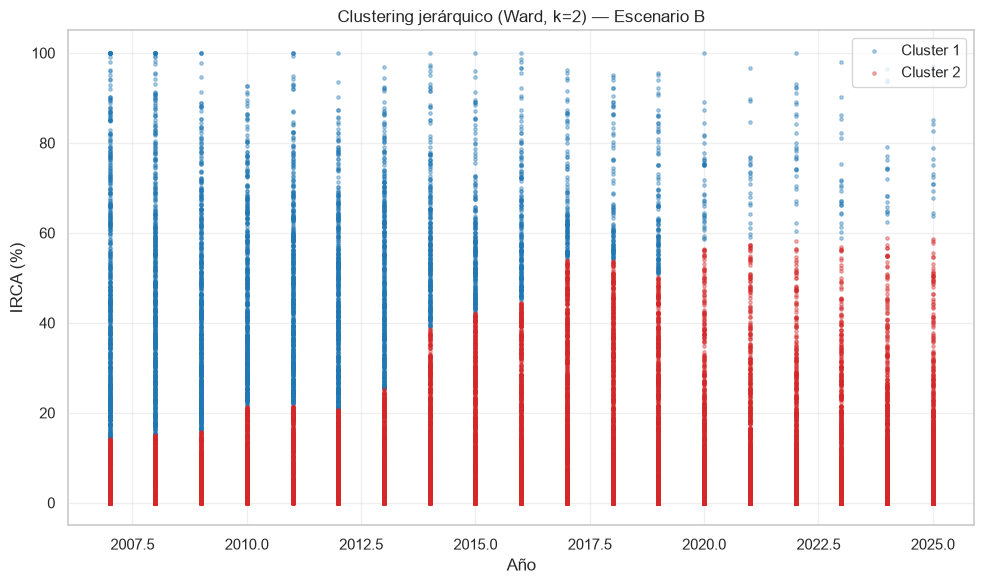

In [74]:
# --- Escenario B: dispersión IRCA vs Año coloreada por cluster jerárquico (k=2) ---
fig, ax = plt.subplots(figsize=(10, 6))
colores = {1: "#1f77b4", 2: "#d62728", 3: "#2ca02c"}
for c in sorted(set(labels_B_j2)):
    sub = caract_jer[caract_jer["j_B_2"] == c]
    ax.scatter(sub["Año"], sub["IRCA"], s=6, alpha=0.35, color=colores[c],
               label=f"Cluster {c}")
ax.set_title("Clustering jerárquico (Ward, k=2) — Escenario B")
ax.set_xlabel("Año"); ax.set_ylabel("IRCA (%)")
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

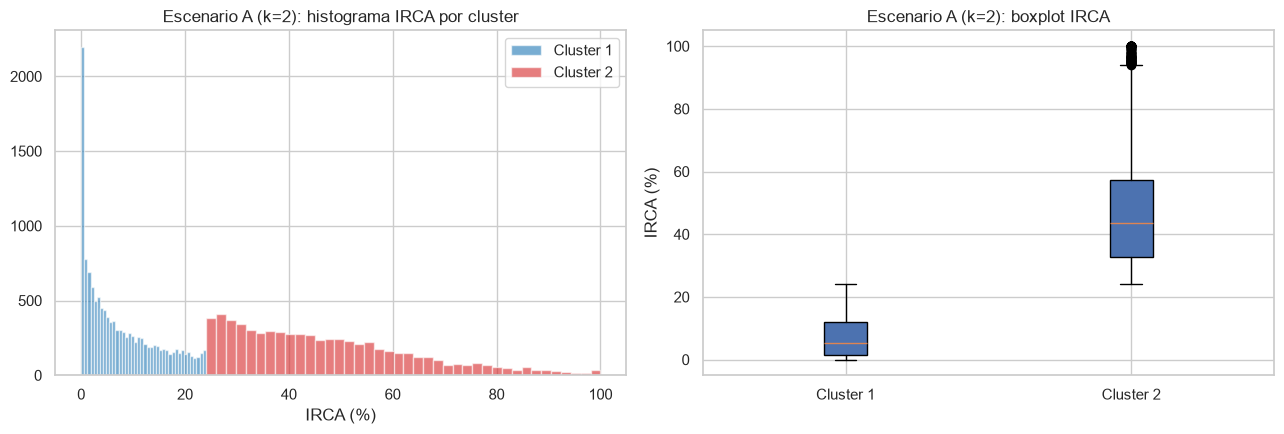

In [75]:
# --- Escenario A: distribución del IRCA por cluster (k=2) ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for c in sorted(set(labels_A_j2)):
    sub = caract_jer[caract_jer["j_A_2"] == c]
    axes[0].hist(sub["IRCA"], bins=40, alpha=0.6, color=colores[c], label=f"Cluster {c}")
axes[0].set_title("Escenario A (k=2): histograma IRCA por cluster")
axes[0].set_xlabel("IRCA (%)"); axes[0].legend()

axes[1].boxplot([caract_jer[caract_jer["j_A_2"] == c]["IRCA"] for c in sorted(set(labels_A_j2))],
                patch_artist=True)
axes[1].set_xticklabels([f"Cluster {c}" for c in sorted(set(labels_A_j2))])
axes[1].set_title("Escenario A (k=2): boxplot IRCA")
axes[1].set_ylabel("IRCA (%)")
plt.tight_layout()
plt.show()

### 3.3.9 Métricas finales de la configuración seleccionada

Se reportan las métricas de la configuración principal (k=2) y de la alternativa (k=3).

In [76]:
def metricas(X, labels, nombre):
    sil = silhouette_score(X, labels)
    db = davies_bouldin_score(X, labels)
    ch = calinski_harabasz_score(X, labels)
    print(f"{nombre}: Silhouette={sil:.4f} | Davies-Bouldin={db:.4f} | Calinski-Harabasz={ch:.1f}")
    return sil, db, ch

m_A2 = metricas(X_A, labels_A_j2, "Escenario A (k=2)")
m_B2 = metricas(X_B, labels_B_j2, "Escenario B (k=2)")
m_A3 = metricas(X_A, labels_A_j3, "Escenario A (k=3)")
m_B3 = metricas(X_B, labels_B_j3, "Escenario B (k=3)")

Escenario A (k=2): Silhouette=0.6734 | Davies-Bouldin=0.5012 | Calinski-Harabasz=52114.5


Escenario B (k=2): Silhouette=0.4111 | Davies-Bouldin=0.9515 | Calinski-Harabasz=13259.1


Escenario A (k=3): Silhouette=0.6392 | Davies-Bouldin=0.5208 | Calinski-Harabasz=65388.7


Escenario B (k=3): Silhouette=0.3767 | Davies-Bouldin=0.8970 | Calinski-Harabasz=16051.6


### 3.3.10 Comparación entre escenarios A y B

- **Escenario A (solo IRCA):** la jerarquía refleja el **perfil de riesgo puro**. En k=2 la
  separación es clara: un grupo de riesgo bajo/medio (IRCA ≈7, n=12.984) y uno de riesgo alto
  (IRCA ≈47, n=6.626). En k=3 se añade una graduación intermedia (≈36).

- **Escenario B (IRCA + Año):** la jerarquía incorpora además la **dimensión temporal**. En k=2
  separa un grupo asociado a IRCA elevado y años promedio más tempranos (IRCA ≈49, año ≈2011) de
  otro asociado a IRCA bajo y años promedio más recientes (IRCA ≈11, año ≈2017).

  > En términos **descriptivos**, se observa una **asociación** entre los grupos, sus niveles de
  > IRCA y los periodos temporales: los conglomerados con IRCA más alto tienden a coincidir con
  > años anteriores y los de IRCA más bajo con años posteriores. No se afirma causalidad ni una
  > "mejora general demostrada" del IRCA en el tiempo; solo se describe la covariación observada
  > en la partición.

**Conclusión:** ambos escenarios revelan una estructura de **riesgo dominante**, y el escenario
B añade la **separación temporal**. En cuanto a la elección de k, la silueta coincide en
favorecer **k=2** como corte principal (las demás métricas no son unánimes, véase §3.3.5).

### 3.3.11 Limitaciones y decisiones metodológicas

**Limitaciones:**

1. **Costo computacional/memoria:** la matriz condensada ocupa ≈1.5 GB; con conjuntos mucho
   mayores, el linkage dejaría de ser viable y habría que usar aglomeración con muestreo.
2. **Dendrograma ilegible:** fue necesario truncar la visualización (lastp=30); el dendrograma
   completo con 19.610 hojas no aporta información legible.
3. **Falta de consenso entre métricas para elegir k:** la silueta favorece k=2 en ambos
   escenarios, pero Davies-Bouldin favorece k=5 en B y Calinski-Harabasz alcanza su máximo en
   valores altos (k=8 en A, k=6 en B), que no son operativamente útiles. No existe una solución
   "óptima" inequívoca.

**Decisiones:**

- Método de enlace: **Ward** (grupos compactos, coherente con euclidiana + z-score).
- Aplicación sobre el **conjunto completo** (sin submuestrear el algoritmo); el submuestreo se
  usó **solo** para el dendrograma de visualización.
- Configuración principal **k=2**, elegida **priorizando la silueta y la simplicidad** ante la
  falta de consenso; alternativa **k=3** (interpretación).
- No se forzó k=3 para coincidir con K-Means.

### 3.3.12 Guardado de resultados

Se guardan las jerarquías, etiquetas, métricas y caracterización para trazabilidad.

In [77]:
resultados_jerarquico = {
    "Z_A": Z_A, "Z_B": Z_B,                 # jerarquías (linkage Ward)
    "labels_A_j2": labels_A_j2, "labels_B_j2": labels_B_j2,
    "labels_A_j3": labels_A_j3, "labels_B_j3": labels_B_j3,
    "metodo_enlace": "ward",
    "metricas": {"A_k2": m_A2, "B_k2": m_B2, "A_k3": m_A3, "B_k3": m_B3},
    "caracterizacion_jer": caract_jer,
    "k_principal": 2,
    "k_alternativo": 3,
}

with open("data_etapa3_jerarquico.pkl", "wb") as f:
    pickle.dump(resultados_jerarquico, f)

print("Resultados de clustering jerárquico guardados en: data_etapa3_jerarquico.pkl")
print()
print("Subetapa 3.3 (Clustering jerárquico) completada — listo para revisión.")

Resultados de clustering jerárquico guardados en: data_etapa3_jerarquico.pkl

Subetapa 3.3 (Clustering jerárquico) completada — listo para revisión.


---
# Etapa 4 — Configuración del análisis comparativo y de interpretación

## 4.1 Inspección de los resultados guardados y verificación de trazabilidad

Antes de comparar e interpretar, se **inspeccionan** los archivos `.pkl` generados por los tres
algoritmos (K-Means, DBSCAN y jerárquico) y se **verifica**:

1. Las etiquetas de cada algoritmo en los escenarios A y B.
2. Las métricas disponibles.
3. La **correspondencia** de las etiquetas con las **19.610 observaciones** municipales.
4. La disponibilidad de **metadatos** y de las **variables originales** (IRCA y Año).

**Nota:** esta etapa **no reentrena modelos ni modifica** las etapas anteriores; solo lee los
resultados persistidos y comprueba su integridad.

In [78]:
# --- Carga de los objetos persistidos ---
import pickle

datos_etapa2 = pickle.load(open("data_etapa2_preparados.pkl", "rb"))
KMeans_res   = pickle.load(open("data_etapa3_kmeans.pkl", "rb"))
DBSCAN_res   = pickle.load(open("data_etapa3_dbscan.pkl", "rb"))
Jerarq_res   = pickle.load(open("data_etapa3_jerarquico.pkl", "rb"))

# Referencias clave
N = len(datos_etapa2["df_municipal"])   # 19.610
metadatos = datos_etapa2["metadatos"]
df_municipal = datos_etapa2["df_municipal"]

print("N observaciones (df_municipal):", N)
print("Metadatos shape:", metadatos.shape)
print("X_A_scaled:", datos_etapa2["X_A_scaled"].shape, "| X_B_scaled:", datos_etapa2["X_B_scaled"].shape)
print()
print("Claves cargadas:")
print("  K-Means :", sorted(KMeans_res.keys()))
print("  DBSCAN  :", sorted(DBSCAN_res.keys()))
print("  Jerárq. :", sorted(Jerarq_res.keys()))

N observaciones (df_municipal): 19610
Metadatos shape: (19610, 10)
X_A_scaled: (19610, 1) | X_B_scaled: (19610, 2)

Claves cargadas:
  K-Means : ['K', 'caracterizacion', 'kmeans_A', 'kmeans_B', 'labels_A', 'labels_B', 'sil_A', 'sil_B']
  DBSCAN  : ['caracterizacion_db', 'dbscan_A', 'dbscan_B', 'eps_A', 'eps_B', 'labels_A', 'labels_B', 'min_samples', 'n_inviable', 'n_irka80', 'sil_A_db', 'sil_B_db']
  Jerárq. : ['Z_A', 'Z_B', 'caracterizacion_jer', 'k_alternativo', 'k_principal', 'labels_A_j2', 'labels_A_j3', 'labels_B_j2', 'labels_B_j3', 'metodo_enlace', 'metricas']


### 4.1.1 Etiquetas y métricas de cada algoritmo

Se resumen las etiquetas (y su cardinalidad) y las métricas disponibles por algoritmo y
escenario.

In [79]:
# --- Etiquetas: longitud y valores únicos ---
def info_etiquetas(lab, nombre, N):
    vals = sorted(set(lab.tolist()))
    n_ruido = int((lab == -1).sum()) if -1 in lab else 0
    print(f"{nombre}: len={len(lab)} (coincide N={len(lab)==N}), "
          f"valores={vals}, ruido(-1)={n_ruido}")

print("=== K-Means (K=3, sil_A=%.4f, sil_B=%.4f) ===" % (KMeans_res['sil_A'], KMeans_res['sil_B']))
info_etiquetas(KMeans_res['labels_A'], "  labels_A", N)
info_etiquetas(KMeans_res['labels_B'], "  labels_B", N)
print()

print("=== DBSCAN (eps_A=%.2f, eps_B=%.2f, min_samples=%d) ===" %
      (DBSCAN_res['eps_A'], DBSCAN_res['eps_B'], DBSCAN_res['min_samples']))
info_etiquetas(DBSCAN_res['labels_A'], "  labels_A", N)
info_etiquetas(DBSCAN_res['labels_B'], "  labels_B", N)
print(f"  sil_A=%.4f, sil_B=%.4f" % (DBSCAN_res['sil_A_db'], DBSCAN_res['sil_B_db']))
print()

print("=== Jerárquico (ward, k_principal=%d, sil_A_k2=%.4f) ===" %
      (Jerarq_res['k_principal'], Jerarq_res['metricas']['A_k2'][0]))
info_etiquetas(Jerarq_res['labels_A_j2'], "  labels_A_k2", N)
info_etiquetas(Jerarq_res['labels_A_j3'], "  labels_A_k3", N)
info_etiquetas(Jerarq_res['labels_B_j2'], "  labels_B_k2", N)
info_etiquetas(Jerarq_res['labels_B_j3'], "  labels_B_k3", N)

=== K-Means (K=3, sil_A=0.6446, sil_B=0.4690) ===
  labels_A: len=19610 (coincide N=True), valores=[0, 1, 2], ruido(-1)=0
  labels_B: len=19610 (coincide N=True), valores=[0, 1, 2], ruido(-1)=0

=== DBSCAN (eps_A=0.02, eps_B=0.20, min_samples=5) ===
  labels_A: len=19610 (coincide N=True), valores=[0, 1, 2], ruido(-1)=0
  labels_B: len=19610 (coincide N=True), valores=[-1, 0, 1, 2], ruido(-1)=5
  sil_A=0.6368, sil_B=0.4554

=== Jerárquico (ward, k_principal=2, sil_A_k2=0.6734) ===
  labels_A_k2: len=19610 (coincide N=True), valores=[1, 2], ruido(-1)=0
  labels_A_k3: len=19610 (coincide N=True), valores=[1, 2, 3], ruido(-1)=0
  labels_B_k2: len=19610 (coincide N=True), valores=[1, 2], ruido(-1)=0
  labels_B_k3: len=19610 (coincide N=True), valores=[1, 2, 3], ruido(-1)=0


In [80]:
# --- Métricas completas del jerárquico (Silhouette, Davies-Bouldin, Calinski-Harabasz) ---
print("Métricas del clustering jerárquico:")
for clave, (sil, db, ch) in Jerarq_res['metricas'].items():
    print(f"  {clave}: Silhouette={sil:.4f} | Davies-Bouldin={db:.4f} | Calinski-Harabasz={ch:.1f}")

Métricas del clustering jerárquico:
  A_k2: Silhouette=0.6734 | Davies-Bouldin=0.5012 | Calinski-Harabasz=52114.5
  B_k2: Silhouette=0.4111 | Davies-Bouldin=0.9515 | Calinski-Harabasz=13259.1
  A_k3: Silhouette=0.6392 | Davies-Bouldin=0.5208 | Calinski-Harabasz=65388.7
  B_k3: Silhouette=0.3767 | Davies-Bouldin=0.8970 | Calinski-Harabasz=16051.6


### 4.1.2 Correspondencia con las 19.610 observaciones y alineación con metadatos

Se verifica que todas las etiquetas tienen la misma longitud que el conjunto municipal y que
los metadatos están alineados por índice con las variables originales.

In [81]:
# --- Verificación de correspondencia de TODAS las etiquetas ---
etiquetas = {
    "KM A": KMeans_res['labels_A'], "KM B": KMeans_res['labels_B'],
    "DB A": DBSCAN_res['labels_A'], "DB B": DBSCAN_res['labels_B'],
    "JER A k2": Jerarq_res['labels_A_j2'], "JER B k2": Jerarq_res['labels_B_j2'],
    "JER A k3": Jerarq_res['labels_A_j3'], "JER B k3": Jerarq_res['labels_B_j3'],
}

print("Etiqueta           | longitud | coincide con N")
print("-" * 45)
todas_ok = True
for nombre, lab in etiquetas.items():
    ok = len(lab) == N
    todas_ok = todas_ok and ok
    print(f"{nombre:<18} | {len(lab):>8} | {'SÍ' if ok else 'NO'}")

print("-" * 45)
print("Todas las etiquetas corresponden a 19.610 observaciones:", todas_ok)

# --- Alineación metadatos <-> variables originales ---
print()
print("Alineación metadatos vs df_municipal (índice):", metadatos.index.equals(df_municipal.index))
print("Columnas de metadatos disponibles:")
print("  ", list(metadatos.columns))

Etiqueta           | longitud | coincide con N
---------------------------------------------
KM A               |    19610 | SÍ
KM B               |    19610 | SÍ
DB A               |    19610 | SÍ
DB B               |    19610 | SÍ
JER A k2           |    19610 | SÍ
JER B k2           |    19610 | SÍ
JER A k3           |    19610 | SÍ
JER B k3           |    19610 | SÍ
---------------------------------------------
Todas las etiquetas corresponden a 19.610 observaciones: True

Alineación metadatos vs df_municipal (índice): True
Columnas de metadatos disponibles:
   ['Departamento', 'DepartamentoCodigo', 'Municipio', 'MunicipioCodigo', 'Año', 'IRCAurbano', 'IRCArural', 'Nivel de riesgo', 'Nivel de riesgo urbano', 'Nivel de riesgo rural']


### 4.1.3 Distribución de tamaños de los grupos

Se comparan los tamaños de clusters de cada algoritmo/escenario como verificación adicional de
coherencia.

In [82]:
import pandas as pd, numpy as np

def dist(lab):
    return pd.Series(lab).value_counts().sort_index()

print("Distribución de tamaños de clusters:")
print("  K-Means A:", dist(KMeans_res['labels_A']).to_dict())
print("  K-Means B:", dist(KMeans_res['labels_B']).to_dict())
print("  DBSCAN A :", dist(DBSCAN_res['labels_A']).to_dict())
print("  DBSCAN B :", dist(DBSCAN_res['labels_B']).to_dict())
print("  Jerárquico A k2:", dist(Jerarq_res['labels_A_j2']).to_dict())
print("  Jerárquico B k2:", dist(Jerarq_res['labels_B_j2']).to_dict())

Distribución de tamaños de clusters:
  K-Means A: {0: 5092, 1: 11682, 2: 2836}
  K-Means B: {0: 4506, 1: 7012, 2: 8092}
  DBSCAN A : {0: 19575, 1: 4, 2: 31}
  DBSCAN B : {-1: 5, 0: 19595, 1: 5, 2: 5}
  Jerárquico A k2: {1: 12984, 2: 6626}
  Jerárquico B k2: {1: 4985, 2: 14625}


### 4.1.4 Conclusiones de la inspección

- **Todas las etiquetas** (K-Means, DBSCAN, jerárquico) tienen **longitud 19.610** y coinciden
  con el número de observaciones municipales.
- Los **metadatos** y las **variables originales** (`df_municipal`) están alineados por índice.
- **Métricas disponibles:**
  - K-Means: silueta (A=0.645, B=0.469).
  - DBSCAN: silueta excluyendo ruido (A=0.637, B=0.455); además `n_inviable=358`, `n_irka80=364`.
  - Jerárquico: Silhouette, Davies-Bouldin y Calinski-Harabasz para k=2 y k=3.

La trazabilidad es correcta: los resultados pueden **compararse directamente** entre algoritmos
porque comparten las mismas 19.610 filas, los mismos metadatos y las mismas variables escaladas.

> **Detención para revisión:** esta subetapa (4.1) concluye la inspección. Se espera la
> revisión antes de continuar con la comparación de resultados entre algoritmos.

## 4.2 Evaluación de los modelos con métricas internas

Se consolidan las métricas internas (sin etiquetas verdaderas) calculadas en las subetapas 3.1,
3.2 y 3.3. Se aplican **solo donde son válidas**:

- **Silhouette**: válida cuando hay ≥2 clusters. Para DBSCAN, se calcula **excluyendo el ruido**
  (los puntos −1 no pertenecen a ningún cluster).
- **Davies-Bouldin** y **Calinski-Harabasz**: calculadas para el jerárquico (k=2 y k=3).

In [83]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

X_A = datos_etapa2["X_A_scaled"]
X_B = datos_etapa2["X_B_scaled"]

# --- Silhouette por algoritmo/escenario (recalculada desde etiquetas guardadas) ---
def silueta_valida(X, labels, excluir_ruido=False):
    if excluir_ruido:
        mask = labels != -1
        X_e, labels_e = X[mask], labels[mask]
    else:
        X_e, labels_e = X, labels
    n_cl = len(set(labels_e))
    if n_cl < 2:
        return np.nan
    return silhouette_score(X_e, labels_e)

res_metricas = {
    "K-Means A": silueta_valida(X_A, KMeans_res["labels_A"]),
    "K-Means B": silueta_valida(X_B, KMeans_res["labels_B"]),
    "DBSCAN A": silueta_valida(X_A, DBSCAN_res["labels_A"], excluir_ruido=True),
    "DBSCAN B": silueta_valida(X_B, DBSCAN_res["labels_B"], excluir_ruido=True),
    "Jerárquico A (k=2)": silueta_valida(X_A, Jerarq_res["labels_A_j2"]),
    "Jerárquico B (k=2)": silueta_valida(X_B, Jerarq_res["labels_B_j2"]),
    "Jerárquico A (k=3)": silueta_valida(X_A, Jerarq_res["labels_A_j3"]),
    "Jerárquico B (k=3)": silueta_valida(X_B, Jerarq_res["labels_B_j3"]),
}

tabla_sil = pd.DataFrame(list(res_metricas.items()), columns=["Modelo", "Silhouette"])
tabla_sil["Silhouette"] = tabla_sil["Silhouette"].round(4)
tabla_sil

,Modelo,Silhouette
0,K-Means A,0.645
1,K-Means B,0.469
2,DBSCAN A,0.637
3,DBSCAN B,0.455
4,Jerárquico A (k=2),0.673
5,Jerárquico B (k=2),0.411
6,Jerárquico A (k=3),0.639
7,Jerárquico B (k=3),0.377


In [84]:
# --- Davies-Bouldin y Calinski-Harabasz para TODOS los algoritmos válidos ---
# (Para DBSCAN se excluye el ruido -1, pues esas observaciones no pertenecen a ningún cluster.)
def db_ch(X, labels, excluir_ruido=False):
    if excluir_ruido:
        mask = labels != -1
        X_e, labels_e = X[mask], labels[mask]
    else:
        X_e, labels_e = X, labels
    n_validos = len(set(labels_e))
    if n_validos < 2:
        return np.nan, np.nan   # DB/CH no aplican con menos de 2 clusters
    return davies_bouldin_score(X_e, labels_e), calinski_harabasz_score(X_e, labels_e)

filas_dbch = []
entradas = [
    ("K-Means A",      X_A, KMeans_res["labels_A"],          False),
    ("K-Means B",      X_B, KMeans_res["labels_B"],          False),
    ("DBSCAN A",       X_A, DBSCAN_res["labels_A"],          True),
    ("DBSCAN B",       X_B, DBSCAN_res["labels_B"],          True),
    ("Jerárquico A k2",X_A, Jerarq_res["labels_A_j2"],       False),
    ("Jerárquico A k3",X_A, Jerarq_res["labels_A_j3"],       False),
    ("Jerárquico B k2",X_B, Jerarq_res["labels_B_j2"],       False),
    ("Jerárquico B k3",X_B, Jerarq_res["labels_B_j3"],       False),
]
for nombre, X, lab, excl in entradas:
    db_, ch = db_ch(X, lab, excluir_ruido=excl)
    filas_dbch.append({"Modelo": nombre, "Davies-Bouldin": round(db_, 4),
                       "Calinski-Harabasz": round(ch, 1),
                       "n_clusters_validos": len(set(lab[lab != -1]))})

tabla_dbch_completa = pd.DataFrame(filas_dbch)
tabla_dbch_completa

,Modelo,Davies-Bouldin,Calinski-Harabasz,n_clusters_validos
0,K-Means A,0.520,70574.800,3
1,K-Means B,0.770,22825.500,3
2,DBSCAN A,0.225,234.500,3
3,DBSCAN B,0.373,34.900,3
4,Jerárquico A k2,0.501,52114.500,2
5,Jerárquico A k3,0.521,65388.700,3
6,Jerárquico B k2,0.952,13259.100,2
7,Jerárquico B k3,0.897,16051.600,3


## 4.3 Tratamiento del ruido de DBSCAN

DBSCAN marca como ruido (−1) las observaciones aisladas. Para las métricas que asumen que todo
punto pertenece a un cluster (silueta, DB, CH), el ruido **se excluye**. Aquí se documenta la
magnitud del ruido y su composición para no distorsionar la evaluación.

In [85]:
# --- Ruido de DBSCAN por escenario ---
ruido_A = DBSCAN_res["labels_A"] == -1
ruido_B = DBSCAN_res["labels_B"] == -1

print(f"Ruido DBSCAN — Escenario A: {ruido_A.sum()} (0 clusters con ruido; eps_A=0.02)")
print(f"Ruido DBSCAN — Escenario B: {ruido_B.sum()} de {len(ruido_B)} ({ruido_B.mean()*100:.3f}%)")
print()

# Composición del ruido (escenario B): IRCA y nivel de riesgo
caract_db = DBSCAN_res["caracterizacion_db"]
if ruido_B.sum() > 0:
    r = caract_db[caract_db["cluster_B_db"] == -1]
    print("Composición del ruido (Escenario B):")
    print(f"  IRCA: media={r['IRCA'].mean():.2f}, min={r['IRCA'].min():.2f}, max={r['IRCA'].max():.2f}")
    print("  Nivel de riesgo:")
    print(r["Nivel de riesgo"].value_counts().to_string())

Ruido DBSCAN — Escenario A: 0 (0 clusters con ruido; eps_A=0.02)
Ruido DBSCAN — Escenario B: 5 de 19610 (0.025%)

Composición del ruido (Escenario B):
  IRCA: media=93.20, min=84.20, max=100.00
  Nivel de riesgo:
Nivel de riesgo
Inviable sanitariamente    5


## 4.4 Comparación de algoritmos en los escenarios A y B

Se resumen número de clusters (excluido el ruido), tamaño del grupo mayoritario y silueta, para
los tres algoritmos.

In [86]:
def resumen_algoritmo(labels):
    n_cl = len(set(labels)) - (1 if -1 in labels else 0)
    n_ruido = int((labels == -1).sum())
    tam = pd.Series(labels[labels != -1]).value_counts() if (labels != -1).any() else pd.Series(dtype=int)
    return n_cl, n_ruido, (tam.iloc[0] / len(labels) * 100 if len(tam) else np.nan)

filas = []
for nombre, lab, X in [
    ("K-Means A", KMeans_res["labels_A"], X_A),
    ("K-Means B", KMeans_res["labels_B"], X_B),
    ("DBSCAN A", DBSCAN_res["labels_A"], X_A),
    ("DBSCAN B", DBSCAN_res["labels_B"], X_B),
    ("Jerárquico A (k=2)", Jerarq_res["labels_A_j2"], X_A),
    ("Jerárquico B (k=2)", Jerarq_res["labels_B_j2"], X_B),
]:
    n_cl, n_ruido, pct_mayor = resumen_algoritmo(lab)
    sil = res_metricas[nombre]
    filas.append({"Modelo": nombre, "Clusters": n_cl, "Ruido": n_ruido,
                  "% cluster mayor": round(pct_mayor, 1), "Silhouette": round(sil, 4)})

pd.DataFrame(filas)

,Modelo,Clusters,Ruido,% cluster mayor,Silhouette
0,K-Means A,3,0,59.600,0.645
1,K-Means B,3,0,41.300,0.469
2,DBSCAN A,3,0,99.800,0.637
3,DBSCAN B,3,5,99.900,0.455
4,Jerárquico A (k=2),2,0,66.200,0.673
5,Jerárquico B (k=2),2,0,74.600,0.411


## 4.5 Reducción de dimensionalidad (PCA)

Se usa PCA para (a) cuantificar la varianza explicada y (b) proyectar en 2D/3D con fines de
visualización.

- Escenario B (IRCA + Año, 2 variables): PCA reproduce la varianza total en dos componentes
  (se reporta la proporción por componente y sus loadings).
- Para una proyección 3D más rica se usan 4 variables numéricas (IRCA, Año, IRCA urbano, IRCA
  rural). Como urban/rural tienen faltantes, se **imputa por mediana únicamente para esta
  visualización**; los resultados de PCA dependen de esa imputación y no deben interpretarse
  como estructura inferida de los datos completos.

In [87]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# --- PCA Escenario B (IRCA + Año) ---
pca_B = PCA(n_components=2).fit(X_B)
print("PCA Escenario B (IRCA+Año) — varianza explicada:",
      np.round(pca_B.explained_variance_ratio_, 4))
print("Loadings:")
print(pd.DataFrame(pca_B.components_, columns=["IRCA", "Año"], index=["PC1", "PC2"]).round(3).to_string())
X_B_pca = pca_B.transform(X_B)

PCA Escenario B (IRCA+Año) — varianza explicada: [0.6425 0.3575]
Loadings:
      IRCA   Año
PC1 -0.707 0.707
PC2  0.707 0.707


In [88]:
# --- PCA sobre 4 variables numéricas (para visualización 3D) ---
cols_num = ["IRCA", "Año", "IRCAurbano", "IRCArural"]
df_num = df_municipal[cols_num].copy()
for c in ["IRCAurbano", "IRCArural"]:
    df_num[c] = pd.to_numeric(df_num[c], errors="coerce")

n_nan_antes = int(df_num.isna().sum().sum())
# Imputación por mediana (solo para PCA de visualización)
for c in ["IRCAurbano", "IRCArural"]:
    df_num[c] = df_num[c].fillna(df_num[c].median())
print(f"Faltantes antes de imputar (solo para PCA): {n_nan_antes}")
print("Faltantes tras imputación:", int(df_num.isna().sum().sum()))

X_std4 = StandardScaler().fit_transform(df_num)
pca_4 = PCA(n_components=4).fit(X_std4)
print()
print("Varianza explicada (4 variables):", np.round(pca_4.explained_variance_ratio_, 4))
print("Varianza acumulada:", np.round(np.cumsum(pca_4.explained_variance_ratio_), 4))
print()
print("Loadings:")
print(pd.DataFrame(pca_4.components_, columns=cols_num,
                   index=["PC1", "PC2", "PC3", "PC4"]).round(3).to_string())

# Proyección en los 3 primeros componentes
X_pca3 = pca_4.transform(X_std4)[:, :3]

Faltantes antes de imputar (solo para PCA): 11398
Faltantes tras imputación: 0

Varianza explicada (4 variables): [0.5409 0.2136 0.2041 0.0414]
Varianza acumulada: [0.5409 0.7545 0.9586 1.    ]

Loadings:
      IRCA    Año  IRCAurbano  IRCArural
PC1  0.630 -0.341       0.562      0.412
PC2  0.162  0.840      -0.049      0.515
PC3 -0.186 -0.421      -0.555      0.693
PC4  0.736  0.001      -0.611     -0.292


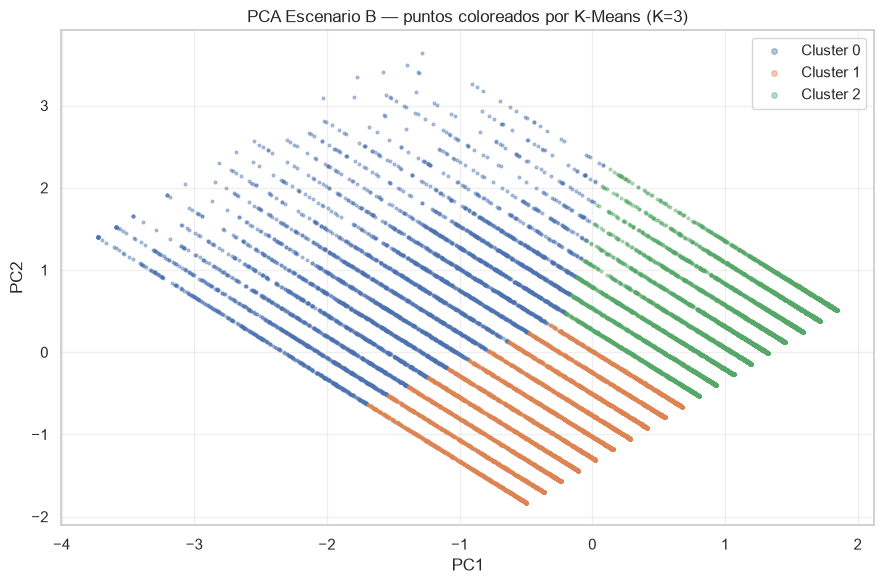

In [89]:
# --- Visualización 2D: PCA del escenario B, coloreado por K-Means ---
fig, ax = plt.subplots(figsize=(9, 6))
for c in sorted(set(KMeans_res["labels_B"])):
    m = KMeans_res["labels_B"] == c
    ax.scatter(X_B_pca[m, 0], X_B_pca[m, 1], s=4, alpha=0.4, label=f"Cluster {c}")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.set_title("PCA Escenario B — puntos coloreados por K-Means (K=3)")
ax.legend(markerscale=2)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

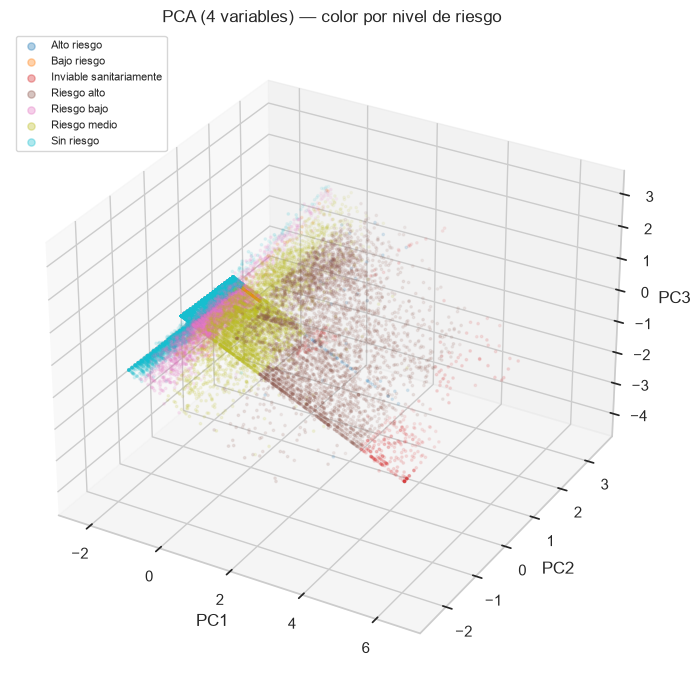

In [90]:
# --- Visualización 3D: PCA de 4 variables, coloreado por nivel de riesgo ---
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.colors as mcolors

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

niveles = sorted(df_municipal["Nivel de riesgo"].dropna().unique())
cmap = plt.get_cmap("tab10", len(niveles))
colores_nivel = {n: cmap(i) for i, n in enumerate(niveles)}

for n in niveles:
    m = df_municipal["Nivel de riesgo"].values == n
    ax.scatter(X_pca3[m, 0], X_pca3[m, 1], X_pca3[m, 2], s=3, alpha=0.35,
               color=colores_nivel[n], label=n)

ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_zlabel("PC3")
ax.set_title("PCA (4 variables) — color por nivel de riesgo")
ax.legend(markerscale=3, loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

## 4.6 Distribución y caracterización de los clusters

Se construye un `DataFrame` unificado (etiquetas de los tres algoritmos + IRCA/Año + metadatos)
para caracterizar la distribución de IRCA, Año y nivel de riesgo por cluster.

In [91]:
# --- DataFrame unificado de caracterización ---
caract = metadatos.copy()
caract["IRCA"] = df_municipal["IRCA"].to_numpy()
caract["Año"] = df_municipal["Año"].to_numpy()
caract["KM_A"] = KMeans_res["labels_A"]
caract["KM_B"] = KMeans_res["labels_B"]
caract["DB_A"] = DBSCAN_res["labels_A"]
caract["DB_B"] = DBSCAN_res["labels_B"]
caract["JER_A2"] = Jerarq_res["labels_A_j2"]
caract["JER_B2"] = Jerarq_res["labels_B_j2"]

print("Caracterización unificada:", caract.shape)
print("Columnas:", list(caract.columns))

Caracterización unificada: (19610, 17)
Columnas: ['Departamento', 'DepartamentoCodigo', 'Municipio', 'MunicipioCodigo', 'Año', 'IRCAurbano', 'IRCArural', 'Nivel de riesgo', 'Nivel de riesgo urbano', 'Nivel de riesgo rural', 'IRCA', 'KM_A', 'KM_B', 'DB_A', 'DB_B', 'JER_A2', 'JER_B2']


In [92]:
# --- Estadísticos de IRCA por cluster (K-Means y jerárquico) ---
def resumen_irca(lab_col, nombre):
    g = caract.groupby(lab_col)["IRCA"].agg(["count", "mean", "median", "min", "max"]).round(2)
    g["%"] = (g["count"] / len(caract) * 100).round(1)
    print(f"--- {nombre} ---")
    print(g.to_string())

resumen_irca("KM_A", "K-Means A")
print()
resumen_irca("KM_B", "K-Means B")
print()
resumen_irca("JER_A2", "Jerárquico A (k=2)")
print()
resumen_irca("JER_B2", "Jerárquico B (k=2)")

--- K-Means A ---
      count   mean  median    min     max      %
KM_A                                            
0      5092 31.200  30.200 18.600  47.200 26.000
1     11682  5.820   4.300  0.000  18.500 59.600
2      2836 63.180  59.800 47.300 100.000 14.500

--- K-Means B ---
      count   mean  median    min     max      %
KM_B                                            
0      4506 54.730  51.850 31.300 100.000 23.000
1      7012 12.080   9.700  0.000  36.900 35.800
2      8092  9.230   5.500  0.000  53.100 41.300

--- Jerárquico A (k=2) ---
        count   mean  median    min     max      %
JER_A2                                            
1       12984  7.360   5.300  0.000  24.000 66.200
2        6626 46.850  43.700 24.100 100.000 33.800

--- Jerárquico B (k=2) ---
        count   mean  median    min     max      %
JER_B2                                            
1        4985 49.060  48.100 14.500 100.000 25.400
2       14625 11.040   6.600  0.000  58.800 74.600


## 4.7 Análisis territorial por departamento y municipio

Se cruzan las etiquetas con departamento y municipio, usando la frecuencia como indicador
descriptivo (sin inferir causalidad). Se recuerda que la frecuencia de un departamento está
condicionada por su número de municipios.

In [93]:
# --- Análisis territorial (top departamentos por cluster) para los 3 algoritmos ---
def top_departamentos(col_lab, nombre):
    print(f"===== {nombre} =====")
    for c in sorted(set(caract[col_lab])):
        sub = caract[caract[col_lab] == c]
        top = sub["Departamento"].value_counts().head(5)
        print(f"  Cluster {c} (IRCA medio={sub['IRCA'].mean():.2f}, n={len(sub)}): "
              + ", ".join(f"{d} ({n})" for d, n in top.items()))

top_departamentos("KM_A", "K-Means A")
print()
top_departamentos("KM_B", "K-Means B")
print()
top_departamentos("DB_B", "DBSCAN B (excluye ruido -1)")
print()
top_departamentos("JER_A2", "Jerárquico A (k=2)")
print()
top_departamentos("JER_B2", "Jerárquico B (k=2)")

===== K-Means A =====
  Cluster 0 (IRCA medio=31.20, n=5092): Boyacá (1082), Nariño (452), Santander (439), Bolívar (295), Cundinamarca (261)
  Cluster 1 (IRCA medio=5.82, n=11682): Antioquia (2074), Cundinamarca (1864), Santander (1068), Boyacá (987), Cauca (535)
  Cluster 2 (IRCA medio=63.18, n=2836): Nariño (440), Bolívar (260), Huila (249), Boyacá (247), Caldas (245)

===== K-Means B =====
  Cluster 0 (IRCA medio=54.73, n=4506): Boyacá (682), Nariño (658), Bolívar (363), Huila (338), Caldas (291)
  Cluster 1 (IRCA medio=12.08, n=7012): Antioquia (1123), Cundinamarca (1064), Boyacá (702), Santander (697), Valle del Cauca (327)
  Cluster 2 (IRCA medio=9.23, n=8092): Antioquia (1078), Cundinamarca (1024), Boyacá (932), Santander (713), Tolima (364)

===== DBSCAN B (excluye ruido -1) =====
  Cluster -1 (IRCA medio=93.20, n=5): Caquetá (1), Cauca (1), Magdalena (1), Bolívar (1), Tolima (1)
  Cluster 0 (IRCA medio=20.65, n=19595): Antioquia (2328), Boyacá (2316), Cundinamarca (2158), San

In [94]:
# --- Cobertura geográfica (municipios y departamentos únicos) por algoritmo ---
def cobertura(col_lab, nombre):
    print(f"===== {nombre} =====")
    for c in sorted(set(caract[col_lab])):
        sub = caract[caract[col_lab] == c]
        print(f"  Cluster {c}: {sub['Municipio'].nunique()} municipios, "
              f"{sub['Departamento'].nunique()} departamentos (n={len(sub)})")

cobertura("KM_A", "K-Means A")
print()
cobertura("DB_B", "DBSCAN B")
print()
cobertura("JER_B2", "Jerárquico B (k=2)")

===== K-Means A =====
  Cluster 0: 841 municipios, 32 departamentos (n=5092)
  Cluster 1: 958 municipios, 33 departamentos (n=11682)
  Cluster 2: 557 municipios, 32 departamentos (n=2836)

===== DBSCAN B =====
  Cluster -1: 5 municipios, 5 departamentos (n=5)
  Cluster 0: 1015 municipios, 33 departamentos (n=19595)
  Cluster 1: 5 municipios, 4 departamentos (n=5)
  Cluster 2: 5 municipios, 3 departamentos (n=5)

===== Jerárquico B (k=2) =====
  Cluster 1: 842 municipios, 32 departamentos (n=4985)
  Cluster 2: 999 municipios, 33 departamentos (n=14625)


## 4.8 Comparación IRCA urbano y rural

Se compara la distribución del IRCA urbano y rural **solo en las observaciones completas** (sin
imputar aquí). Se documenta la proporción de faltantes, que condiciona la lectura. La correlación
urbano-rural se calcula únicamente sobre el subconjunto con ambos valores presentes.

In [95]:
df_ur = df_municipal.copy()
for c in ["IRCAurbano", "IRCArural"]:
    df_ur[c] = pd.to_numeric(df_ur[c], errors="coerce")

print("Faltantes IRCAurbano:", int(df_ur["IRCAurbano"].isna().sum()),
      f"({df_ur['IRCAurbano'].isna().mean()*100:.1f}%)")
print("Faltantes IRCArural:", int(df_ur["IRCArural"].isna().sum()),
      f"({df_ur['IRCArural'].isna().mean()*100:.1f}%)")
print()
print("Estadísticos (sin imputar, sobre observaciones válidas):")
print(pd.DataFrame({
    "IRCA general": df_ur["IRCA"].describe(),
    "IRCA urbano": df_ur["IRCAurbano"].describe(),
    "IRCA rural": df_ur["IRCArural"].describe(),
}).T.round(2).to_string())
print()
print("NOTA técnica: el IRCA rural tiene 51.6% de faltantes; la media rural (≈37.3) se calcula")
print("solo sobre municipios que reportaron zona rural, por lo que no es directamente comparable")
print("con la media general (≈20.7) calculada sobre todos los municipios.")

Faltantes IRCAurbano: 1273 (6.5%)
Faltantes IRCArural: 10125 (51.6%)

Estadísticos (sin imputar, sobre observaciones válidas):
                 count   mean    std   min   25%    50%    75%     max
IRCA general 19610.000 20.710 21.910 0.000 3.100 12.200 33.000 100.000
IRCA urbano  18337.000 14.880 20.430 0.000 1.000  6.000 20.000 100.000
IRCA rural    9485.000 37.340 29.840 0.000 7.500 34.900 64.000 100.000

NOTA técnica: el IRCA rural tiene 51.6% de faltantes; la media rural (≈37.3) se calcula
solo sobre municipios que reportaron zona rural, por lo que no es directamente comparable
con la media general (≈20.7) calculada sobre todos los municipios.


Observaciones con IRCA urbano y rural completos: 9129


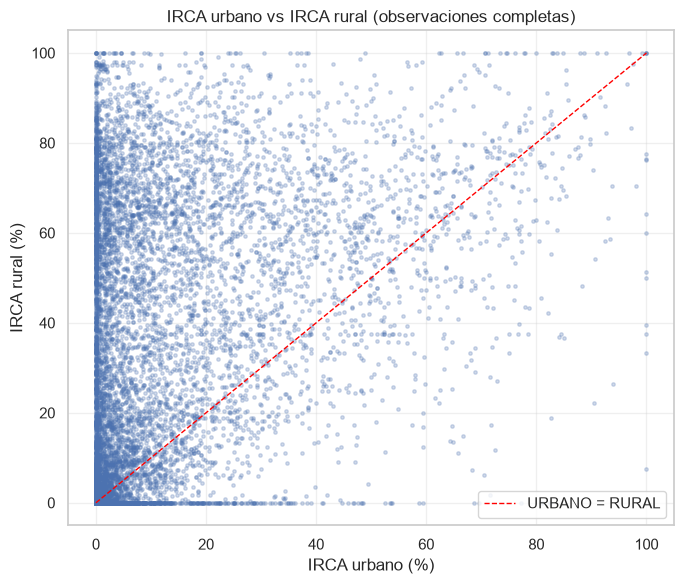

Correlación IRCA urbano vs rural (n=9129): 0.3272


In [96]:
# --- Visualización: IRCA urbano vs rural (observaciones completas) ---
parejas = df_ur[["IRCAurbano", "IRCArural"]].dropna()
print(f"Observaciones con IRCA urbano y rural completos: {len(parejas)}")

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(parejas["IRCAurbano"], parejas["IRCArural"], s=6, alpha=0.25)
ax.plot([0, 100], [0, 100], color="red", linestyle="--", linewidth=1, label="URBANO = RURAL")
ax.set_xlabel("IRCA urbano (%)")
ax.set_ylabel("IRCA rural (%)")
ax.set_title("IRCA urbano vs IRCA rural (observaciones completas)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

corr_ur = parejas["IRCAurbano"].corr(parejas["IRCArural"])
print(f"Correlación IRCA urbano vs rural (n={len(parejas)}): {corr_ur:.4f}")

## 4.9 Patrones temporales y niveles de riesgo

Se examinan (a) la evolución temporal del IRCA promedio y (b) la relación entre los clusters y
los niveles de riesgo, sin afirmar causalidad.

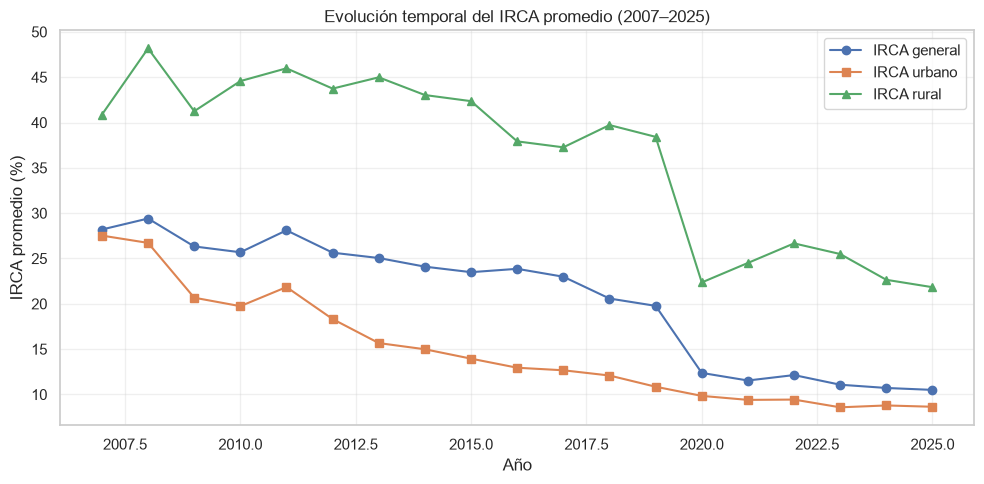

IRCA promedio por año (general):
Año
2007   28.200
2008   29.410
2009   26.330
2010   25.690
2011   28.110
2012   25.640
2013   25.050
2014   24.100
2015   23.490
2016   23.860
2017   22.990
2018   20.580
2019   19.770
2020   12.380
2021   11.540
2022   12.140
2023   11.070
2024   10.720
2025   10.500


In [97]:
# --- Evolución temporal del IRCA promedio (general, urbano, rural) ---
serie_gral = df_municipal.groupby("Año")["IRCA"].mean()
serie_urb = df_ur.groupby("Año")["IRCAurbano"].mean()
serie_rur = df_ur.groupby("Año")["IRCArural"].mean()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(serie_gral.index, serie_gral.values, marker="o", label="IRCA general")
ax.plot(serie_urb.index, serie_urb.values, marker="s", label="IRCA urbano")
ax.plot(serie_rur.index, serie_rur.values, marker="^", label="IRCA rural")
ax.set_xlabel("Año"); ax.set_ylabel("IRCA promedio (%)")
ax.set_title("Evolución temporal del IRCA promedio (2007–2025)")
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("IRCA promedio por año (general):")
print(serie_gral.round(2).to_string())

In [98]:
# --- Cruce cluster (K-Means) vs nivel de riesgo ---
print("Tabla cruzada K-Means A vs Nivel de riesgo:")
print(pd.crosstab(caract["KM_A"], caract["Nivel de riesgo"]).to_string())
print()
print("Distribución de años en el cluster de mayor riesgo (K-Means A):")
c_max = caract.groupby("KM_A")["IRCA"].mean().idxmax()
sub = caract[caract["KM_A"] == c_max]
print(sub["Año"].value_counts().sort_index().to_string())

Tabla cruzada K-Means A vs Nivel de riesgo:
Nivel de riesgo  Alto riesgo  Bajo riesgo  Inviable sanitariamente  Riesgo alto  Riesgo bajo  Riesgo medio  Sin riesgo
KM_A                                                                                                                  
0                         30            0                        0         1735            0          3327           0
1                          0          256                        0            0         3774          1277        6375
2                         35            0                      358         2443            0             0           0

Distribución de años en el cluster de mayor riesgo (K-Means A):
Año
2007    222
2008    251
2009    205
2010    200
2011    230
2012    210
2013    208
2014    204
2015    178
2016    184
2017    180
2018    145
2019    135
2020     65
2021     55
2022     49
2023     39
2024     38
2025     38
